In [1]:
import uproot
import awkward as ak
import numpy as np
import glob
import matplotlib
import matplotlib.pyplot as plt

# plt.style.use('ggplot')

In [2]:
base = "/Users/PITLab/3D_sensors/Processed_data/"
fields = [
    'i_evt',
    'channel',
    'time',
    'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    'risetime',
    'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]

nbins = 20
plot_size = 7

In [3]:
filenames = []
# pattern = f"{base}/proc_F_*AC100W80*high_threshold_trigger.root"
# filenames += glob.glob(pattern)
pattern = f"{base}/proc_F_*AC100W80*_.root"
filenames += glob.glob(pattern)
# filenames = np.array(filenames)

bias_voltages = []
legend_labels = []
object_labels = []

for f in filenames:
    bias_voltage = f.split("_bv")[1].split("_")[0] + "V"
    wafer = f.split(f"{base}proc_F_")[1].split("_strip")[0]
    tag = f.split(f"{base}proc_F_")[1].split("_Ch8_")[1].split("_")[0]
    bias_voltages.append(int(f.split("_bv")[1].split("_")[0]))

    if "low_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 4 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"low_threshold")
    elif "high_threshold_trigger" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 20 mV, Ch8: 40 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_trigger")
    elif "high_threshold" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 10 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_MCP")
    elif "_.root" in f:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 15 mV, Ch8: 20 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"high_threshold_earlyruns")
    else:
        legend_labels.append(wafer+" "+bias_voltage+" "+tag+" "+"Ch4: 12.5 mV, Ch8: 8 mV")
        object_labels.append(wafer+"_"+bias_voltage+"_"+tag+"_"+"init_threshold")

bias_voltages = np.array(bias_voltages)
sort = np.argsort(bias_voltages)
legend_labels = np.array(legend_labels)[sort]
object_labels = np.array(object_labels)[sort]
filenames     = np.array(filenames)    [sort]
bias_voltages = bias_voltages[sort]

print(filenames)
print(legend_labels)
print(object_labels)
print(bias_voltages[sort])

['/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root']
['AC100W80 116V Sr90 Ch4: 15 mV, Ch8: 20 mV']
['AC100W80_116V_Sr90_high_threshold_earlyruns']
[116]


<h3>Category 1: the amplitude fraction is greater than a given number (0.9 for instance), this data point is considered to be at the center of the strip</h3>
<h3>Category 2: the amplitude fraction is less than a given number, this data point is considered to be at the gap between the two leading strips and the x position of the hit is estimated</h3>
<h3></h3>

In [7]:
def draw_grid(ax):
    for i in range(0, 20):
        if i < range_start or i > range_end: continue
        x0 = i*(strip_width + strip_gap)
        y0 = 0
        rect = matplotlib.patches.Rectangle((x0, y0), width = strip_width, height = 1, color = "gray", alpha = 0.3)
        ax.add_patch(rect)
        x0 = i*(strip_width + strip_gap) + strip_width
        rect = matplotlib.patches.Rectangle((x0, y0), width = strip_gap, height = 1, color = "gray", alpha = 0.05)
        ax.add_patch(rect)
        # ax.set_xlim(0, (range_end+3.5)*(strip_width+strip_gap))
    ax.set_xlim((range_start-1.5)*(strip_width+strip_gap), (range_end+1.5)*(strip_width+strip_gap))
    ax.set_xlabel("Hit position X")
    ax.set_ylabel("Fraction of events")
    return ax

# returns the index of the left of the two leading strips, the estimated distance from it
def get_x_position(amp, width, gap, fraction_threshold = 0.9):
    # mask = [True, True, True, True, True, True, True, False]
    # amp = amp[mask]
    
    amplitude_order = np.argsort(amp)[-2::] # select the two leading strips
    strip_order     = np.sort(np.argsort(amp)[-2::])
    # print(amplitude_order)
    # print(strip_order)
    # sprint()
    
    fraction = max(amp[amplitude_order]) / np.sum(amp[amplitude_order])
    
    if (fraction > fraction_threshold): # The leading strip is greater than a specified threshold
        # rel_distance = width / 2
        # if amplitude_order[0] == strip_order[0]: # if the leading strip is the left strip
        #     rel_distance = width / 2
        # else:
        #     rel_distance = gap + width / 2
        x_position = (width+gap)*(amplitude_order[0]+1) - gap - width / 2 # rel_distance
    else: # The hit is between the leading and subleading strips
        if amplitude_order[0] == strip_order[0]: # if the leading strip is the left strip
            rel_distance = gap * (fraction)
        else:
            rel_distance = gap * (1-fraction)
        x_position = (width+gap)*(strip_order    [0]+1) - gap + rel_distance
    
    # if (strip_order[0] == 2 and amplitude_order[0] == 3):
    #     print("Strips 2 and 3: ", strip_order, amplitude_order[0], fraction, x_position)
    
    # if (strip_order[0] == 3 and amplitude_order[0] == 3):
    #     print("Strips 3 and 4: ", strip_order, amplitude_order, , fraction, x_position)
    # print()
    
    return x_position, strip_order, fraction

def get_weighted_time(amp, timestamp):
    amplitude_order = np.argsort(amp)[-2::] # select the two leading strips
    # print(np.multiply(amp[amplitude_order], amp[amplitude_order]), timestamp[amplitude_order])
    # print(np.multiply(np.multiply(amp[amplitude_order], amp[amplitude_order]), timestamp[amplitude_order]))
    weighted_time = np.sum(
        np.multiply(
            np.multiply(amp[amplitude_order], amp[amplitude_order]), timestamp[amplitude_order]
        )
    ) / np.sum(
        np.multiply(amp[amplitude_order], amp[amplitude_order])
    )
    return weighted_time

def get_x_propagation_time(amp, timestamp):
    amplitude_order = np.argsort(amp)[-2::] # select the two leading strips
    # print(np.multiply(amp[amplitude_order], amp[amplitude_order]), timestamp[amplitude_order])
    # print(np.multiply(np.multiply(amp[amplitude_order], amp[amplitude_order]), timestamp[amplitude_order]))
    weighted_time = np.sum(
        np.multiply(
            np.multiply(
                amp[amplitude_order], amp[amplitude_order]
            ), timestamp[amplitude_order]
        )
    ) / np.sum(
        np.multiply(
            amp[amplitude_order], amp[amplitude_order]
        )
    )
    
    return timestamp[amplitude_order[0]] - weighted_time # the time difference between the leading strip and the weighted timestamp

In [8]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

trigger_strip = 3
mcp_channel = 7

for f_i, f in enumerate(filenames):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    # print(pulse[0].fields)
    l = str(object_labels[f_i])
    channel[l] = pulse["channel"]
    time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]

print(amp.keys())

dict_keys(['AC100W80_116V_Sr90_high_threshold_earlyruns'])


dict_keys(['AC100W80_116V_Sr90_high_threshold_earlyruns'])
AC100W80_116V_Sr90_high_threshold_earlyruns
[29, 34.8, 30, 35.7, 38.3, 53.1, 28.5, ..., 30, 37, 30.9, 23.6, 26, 34.6, 73.1]
[1360. 1360. 1360. ... 1360. 1360. 1360.]


/var/folders/rm/fk9q9bcs3t5_x29ybf88ljkh0000j6/T/ipykernel_94286/2709914749.py:101: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax[0][0].set_ylim(0, 1) # len(amp[key])
/var/folders/rm/fk9q9bcs3t5_x29ybf88ljkh0000j6/T/ipykernel_94286/2709914749.py:145: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0][3].legend()
/var/folders/rm/fk9q9bcs3t5_x29ybf88ljkh0000j6/T/ipykernel_94286/2709914749.py:151: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0][4].legend()
/var/folders/rm/fk9q9bcs3t5_x29ybf88ljkh0000j6/T/ipykernel_94286/2709914749.py:158: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with n

0.03307397


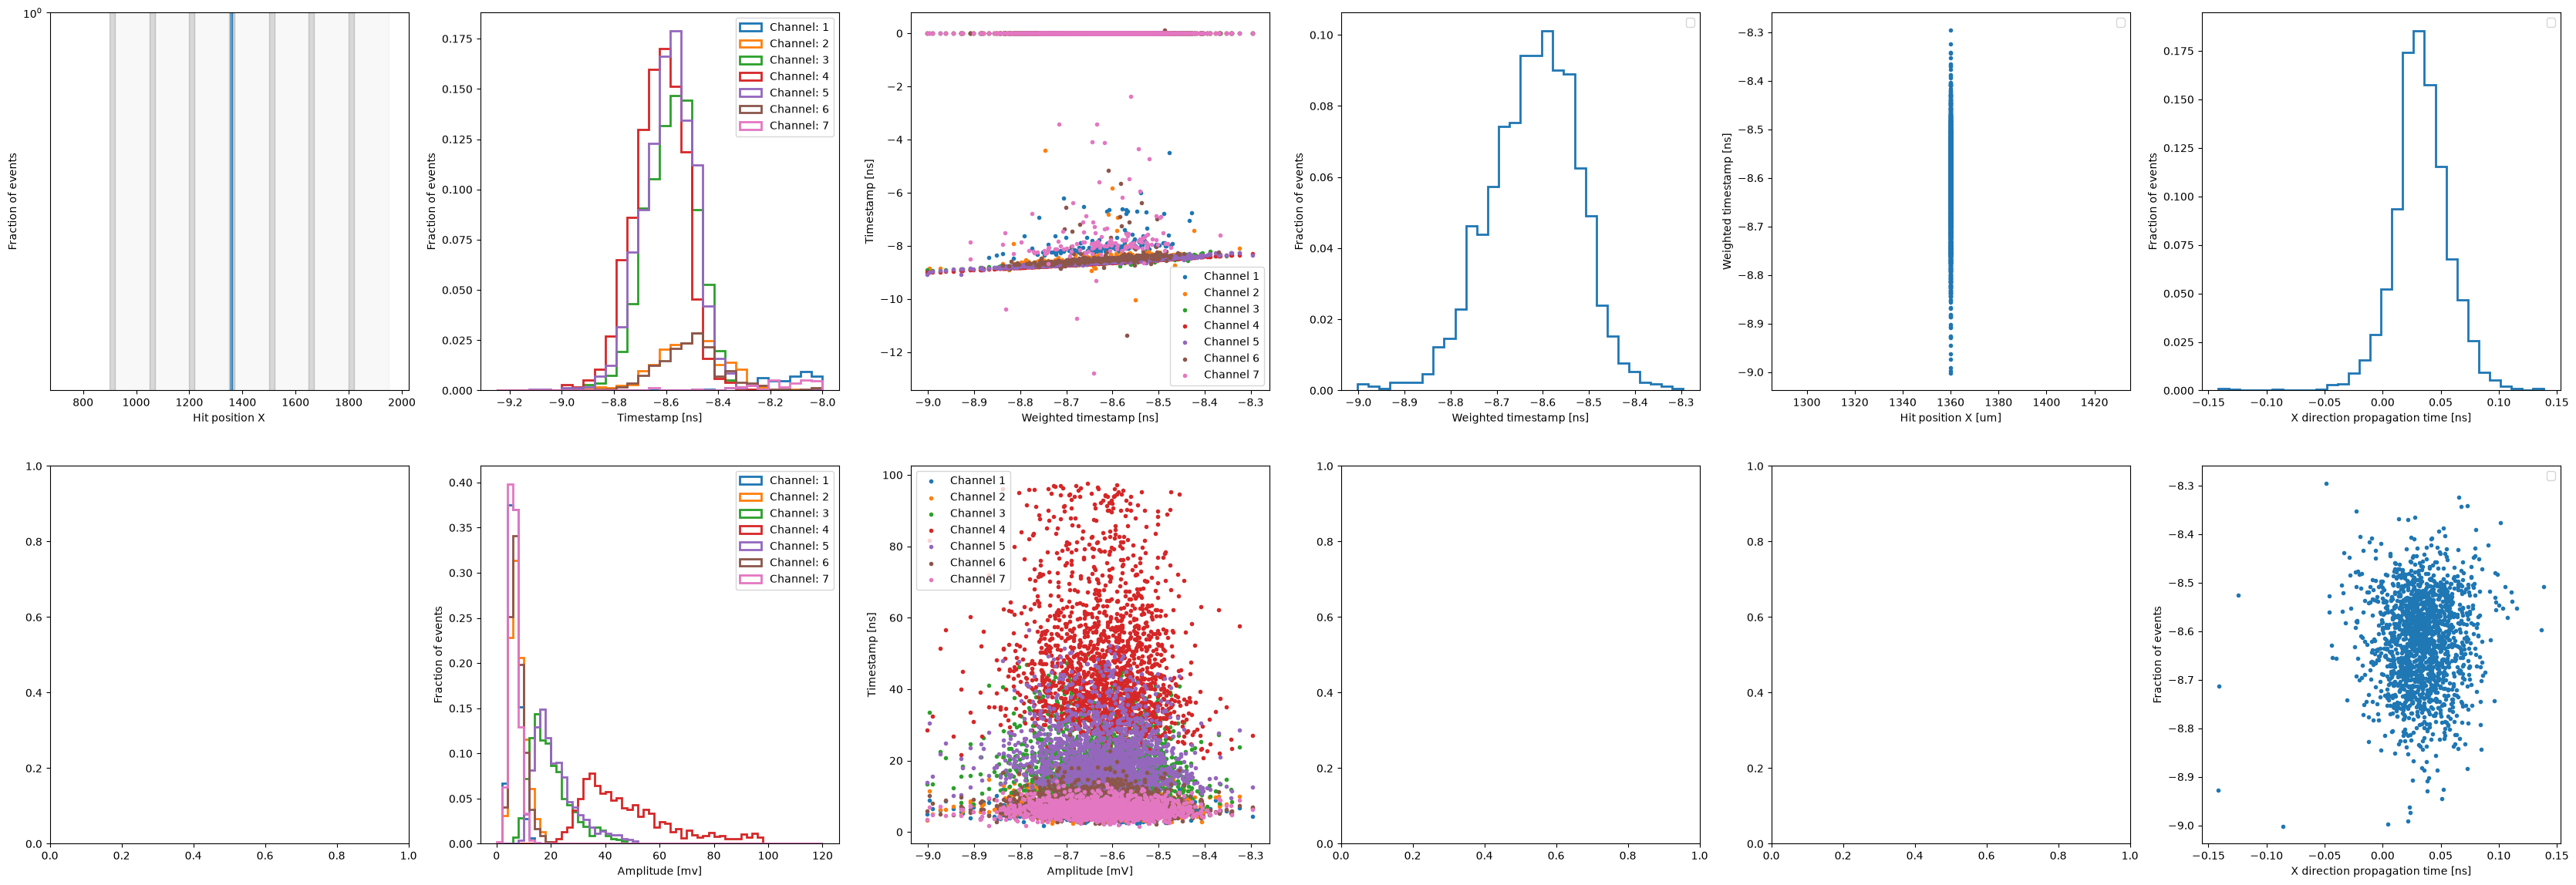

[1360. 1360. 1360. ... 1360. 1360. 1360.]
0.03307397


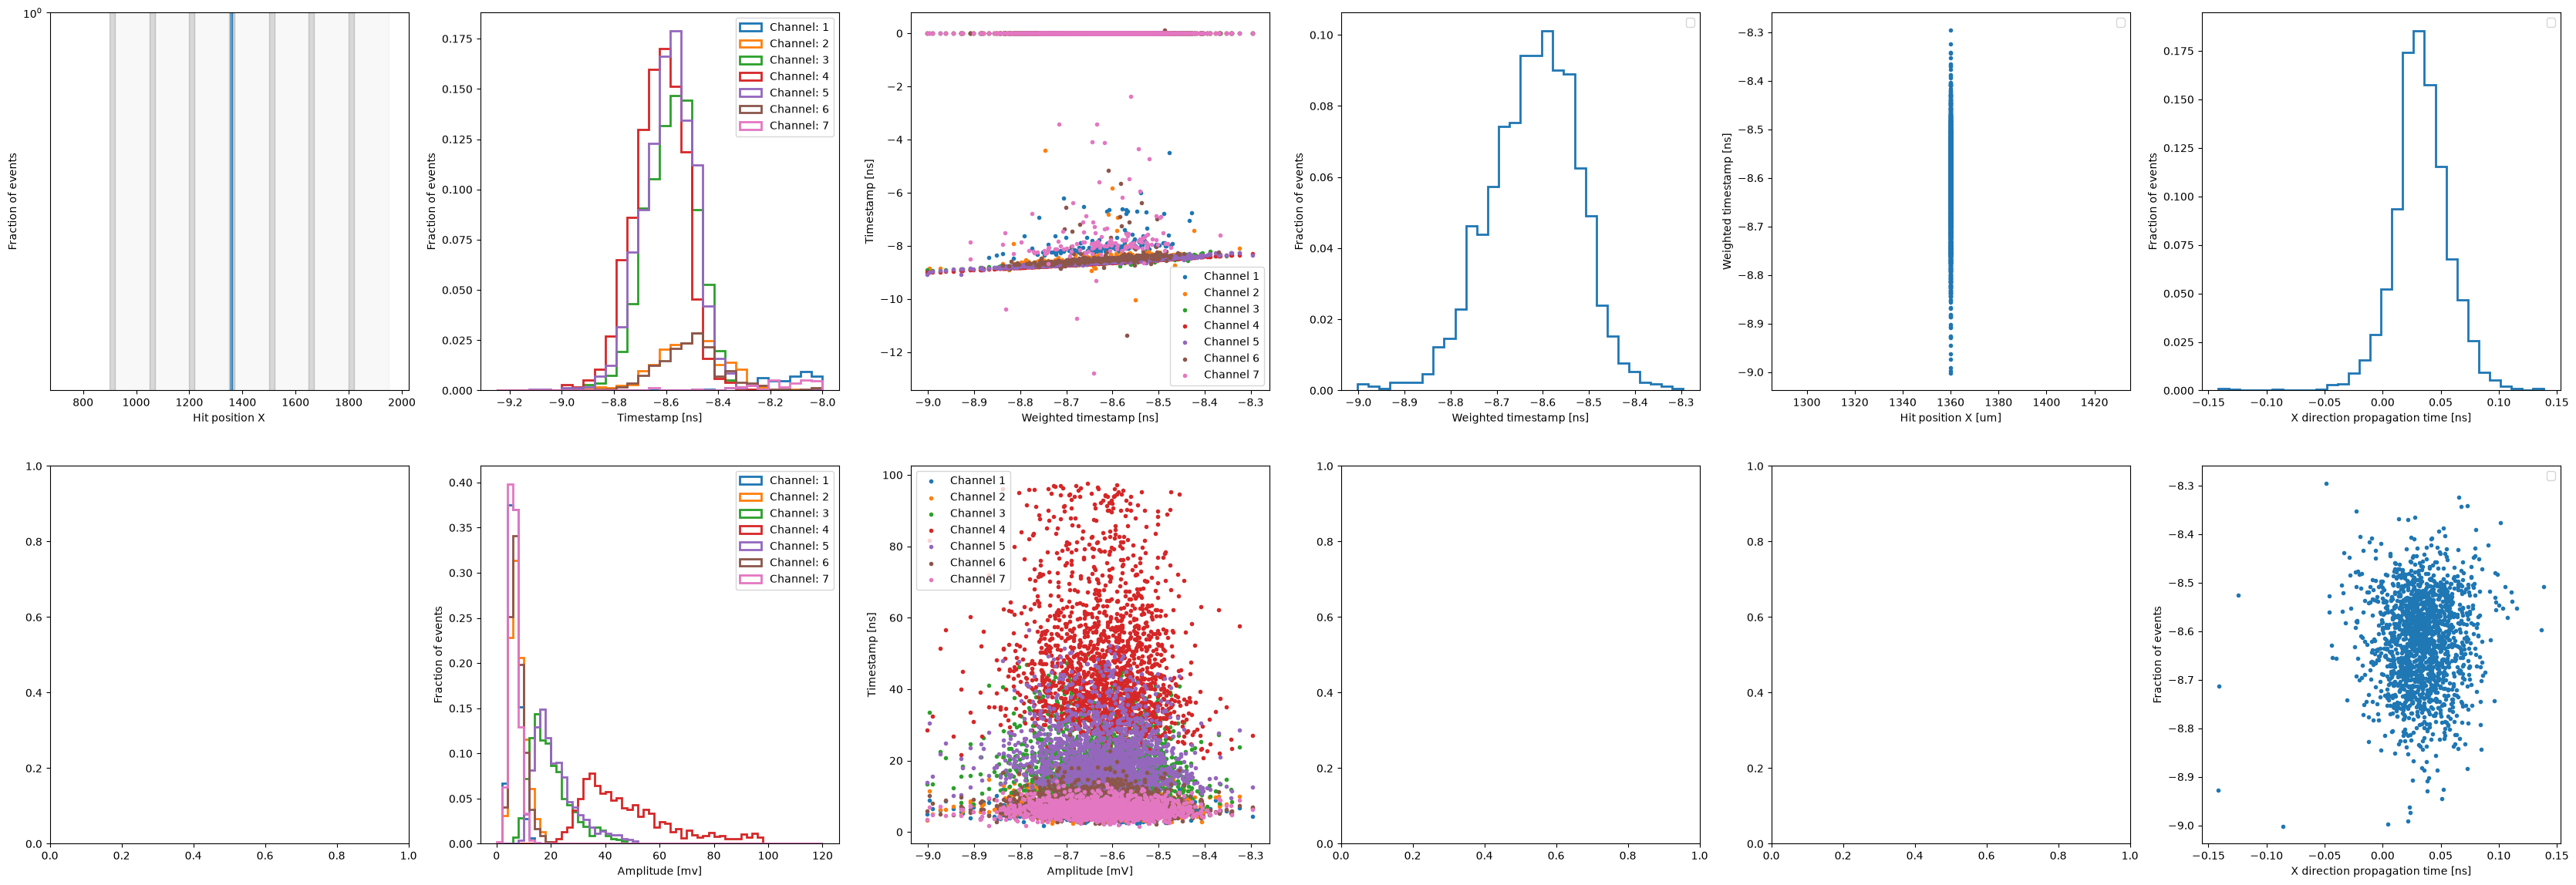

[1360. 1360. 1360. ... 1360. 1360. 1360.]
0.03307397


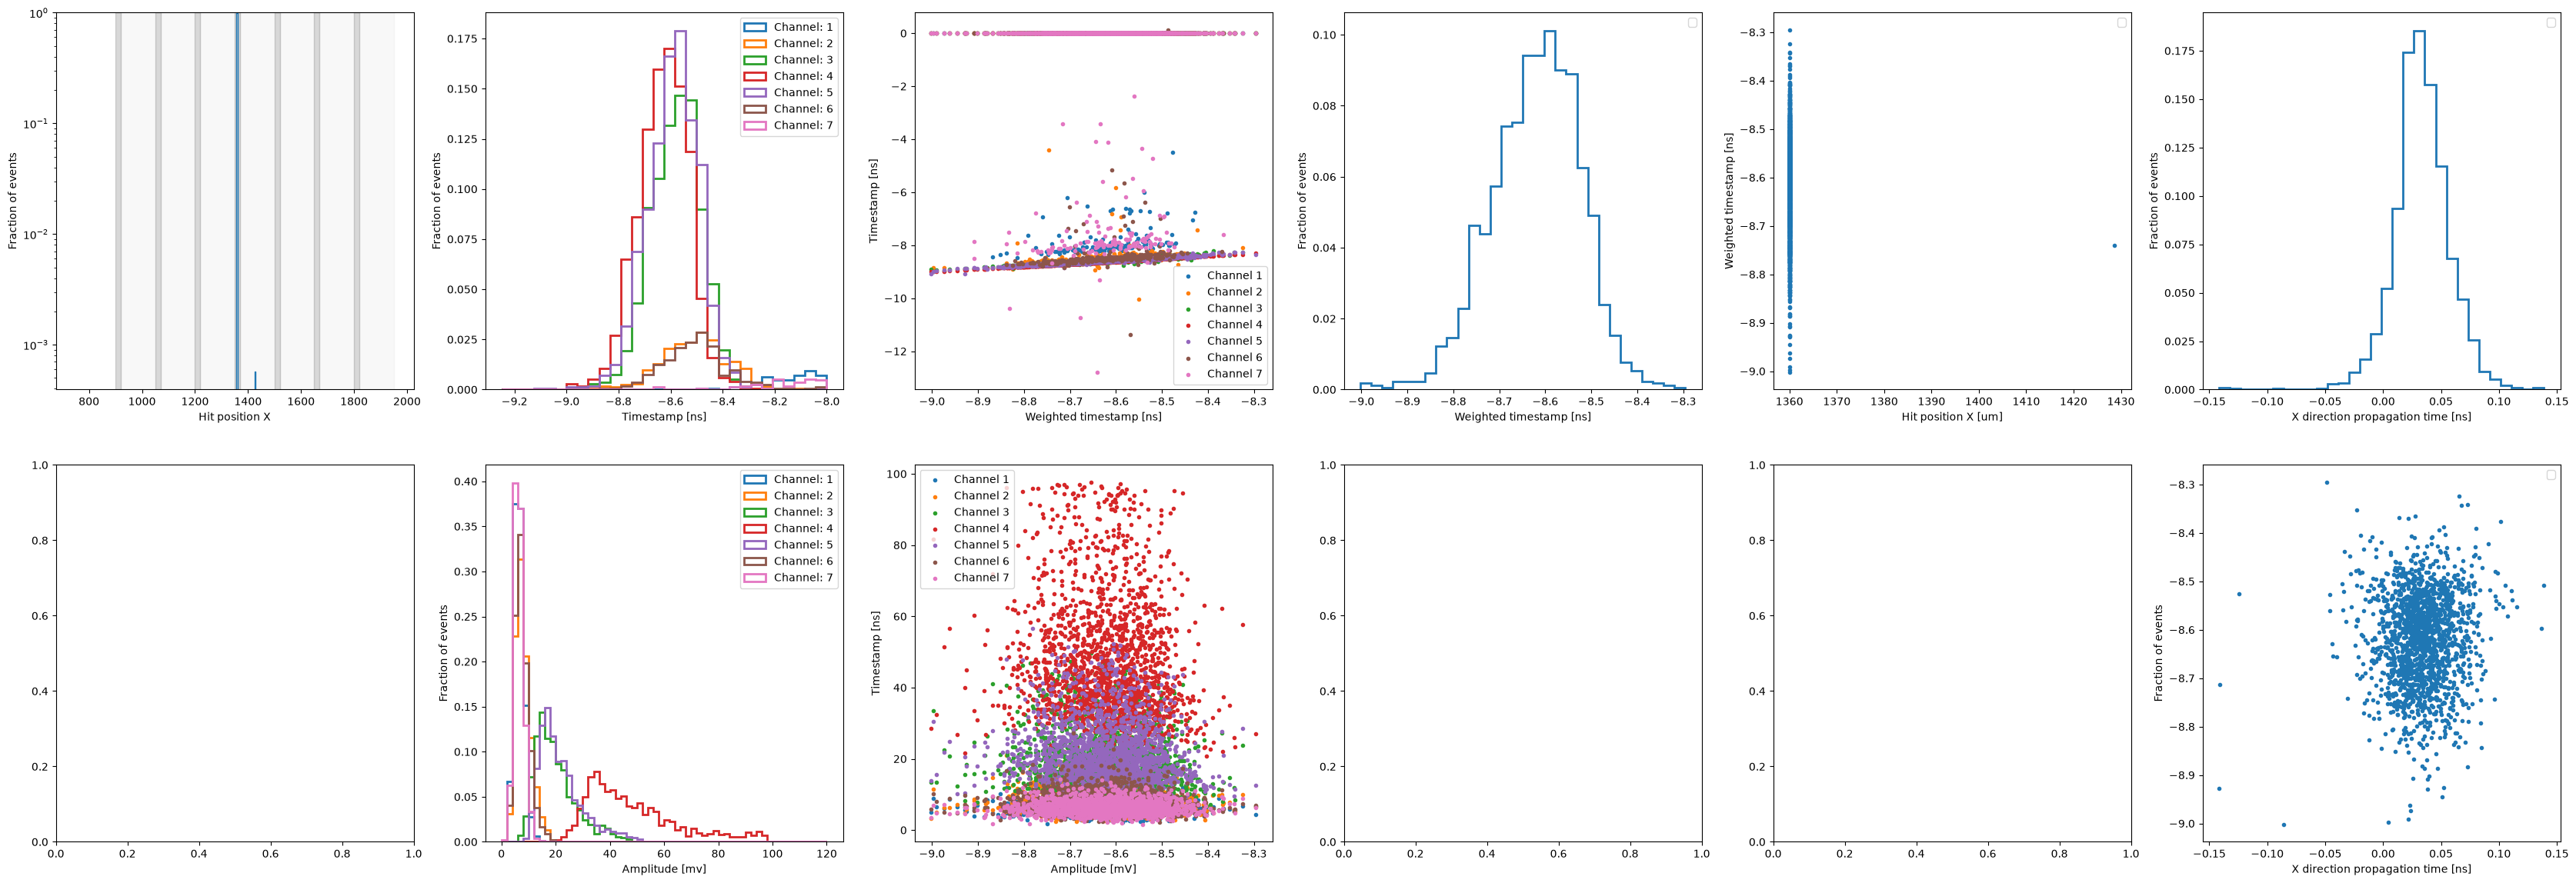

[1360. 1360. 1360. ... 1360. 1360. 1360.]
0.03307397


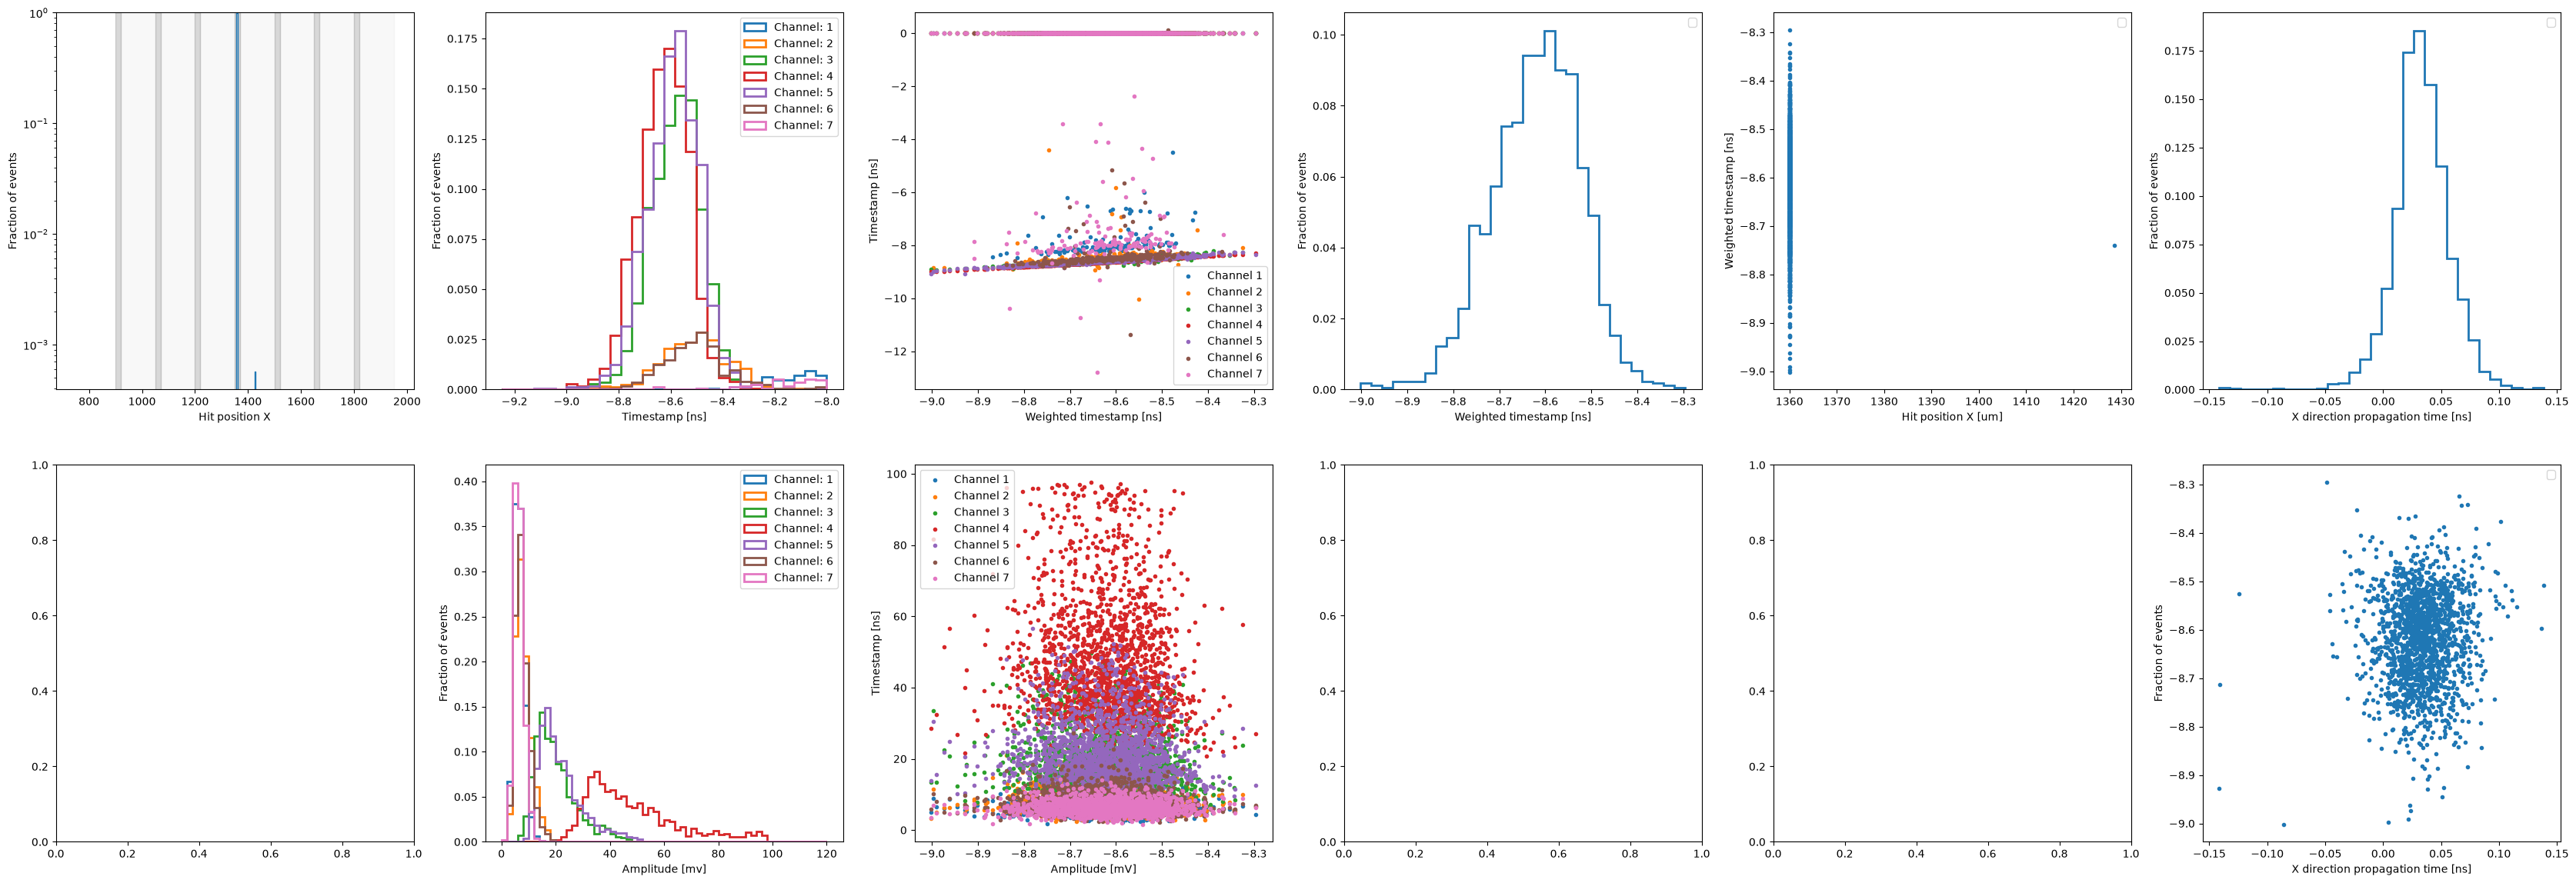

[1360. 1360. 1360. ... 1360. 1360. 1360.]
0.03307397


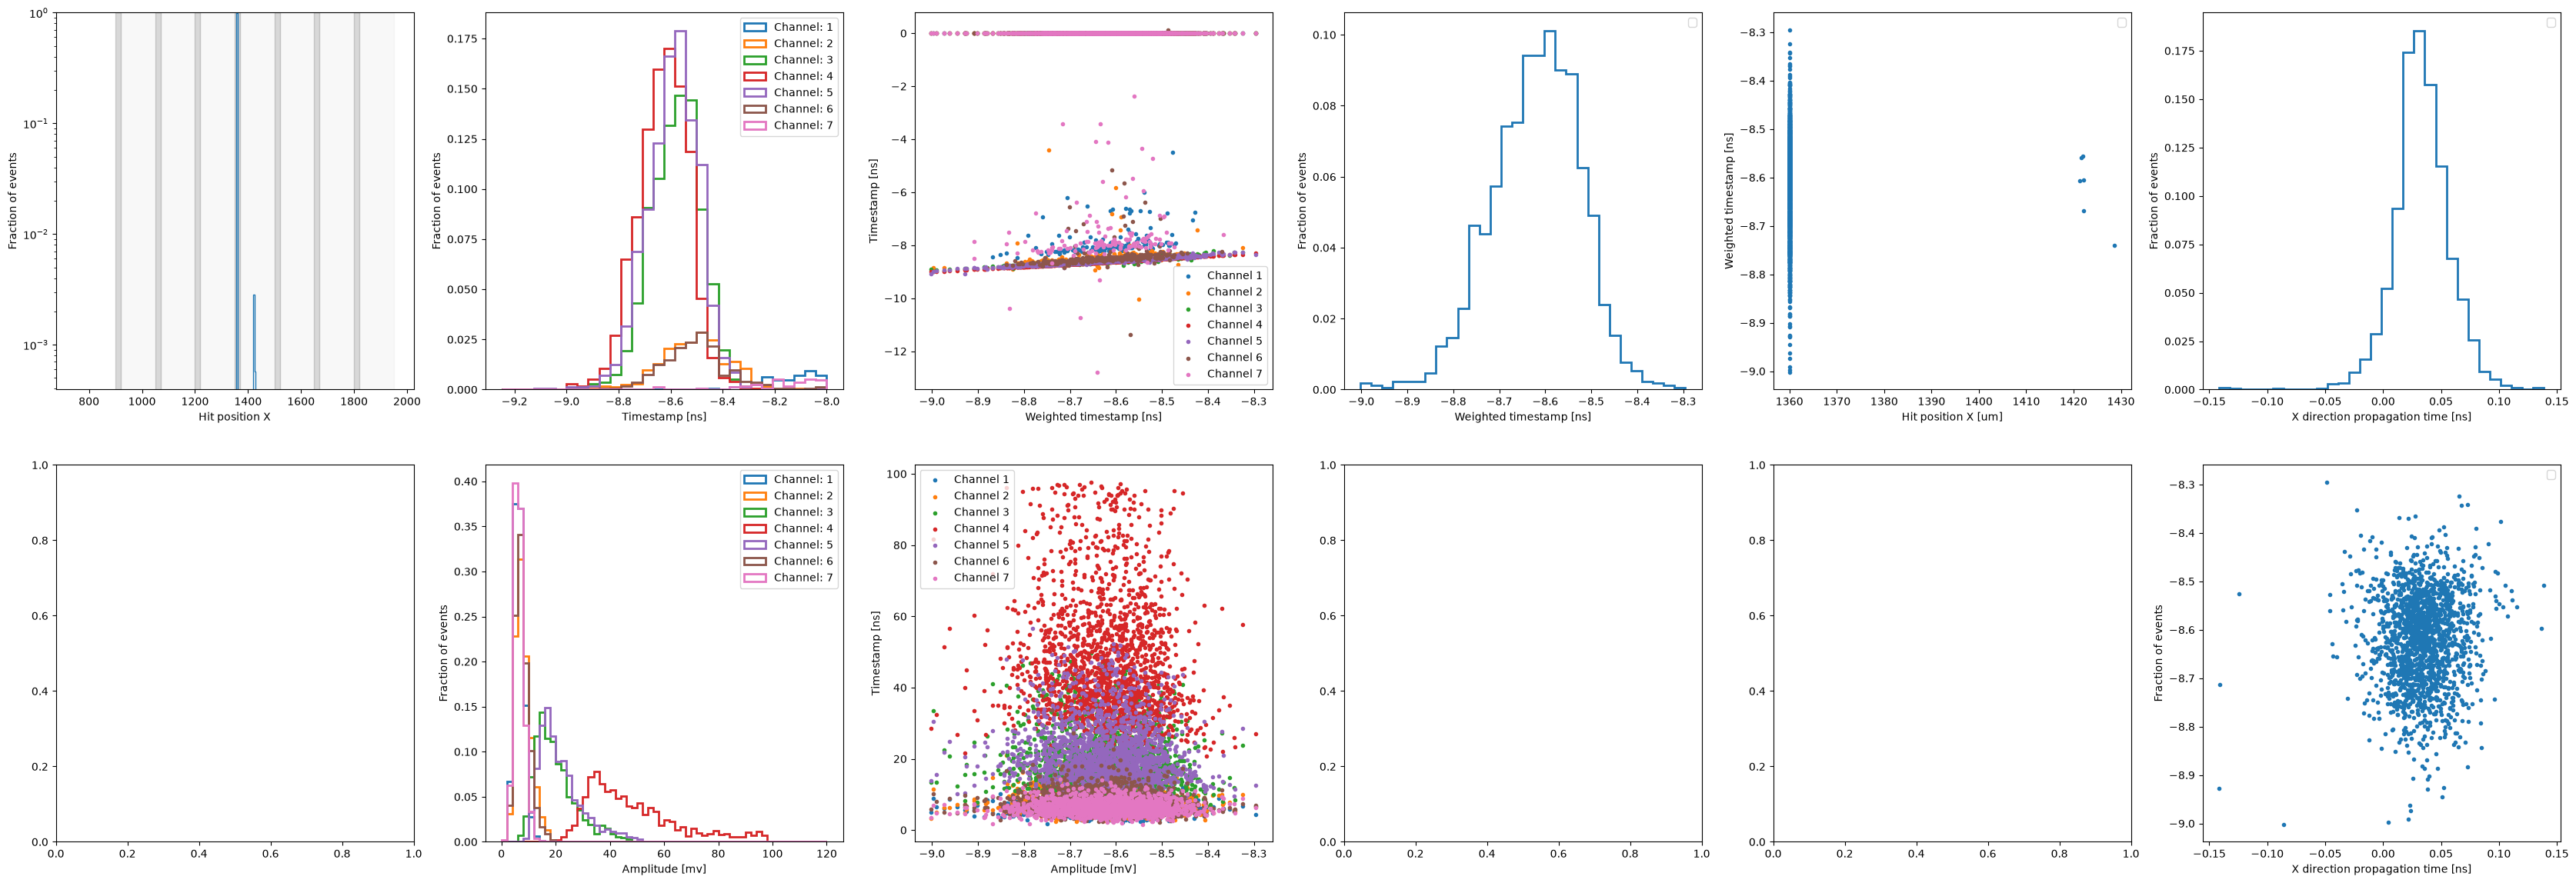

[1360. 1360. 1360. ... 1360. 1360. 1360.]
0.03307397


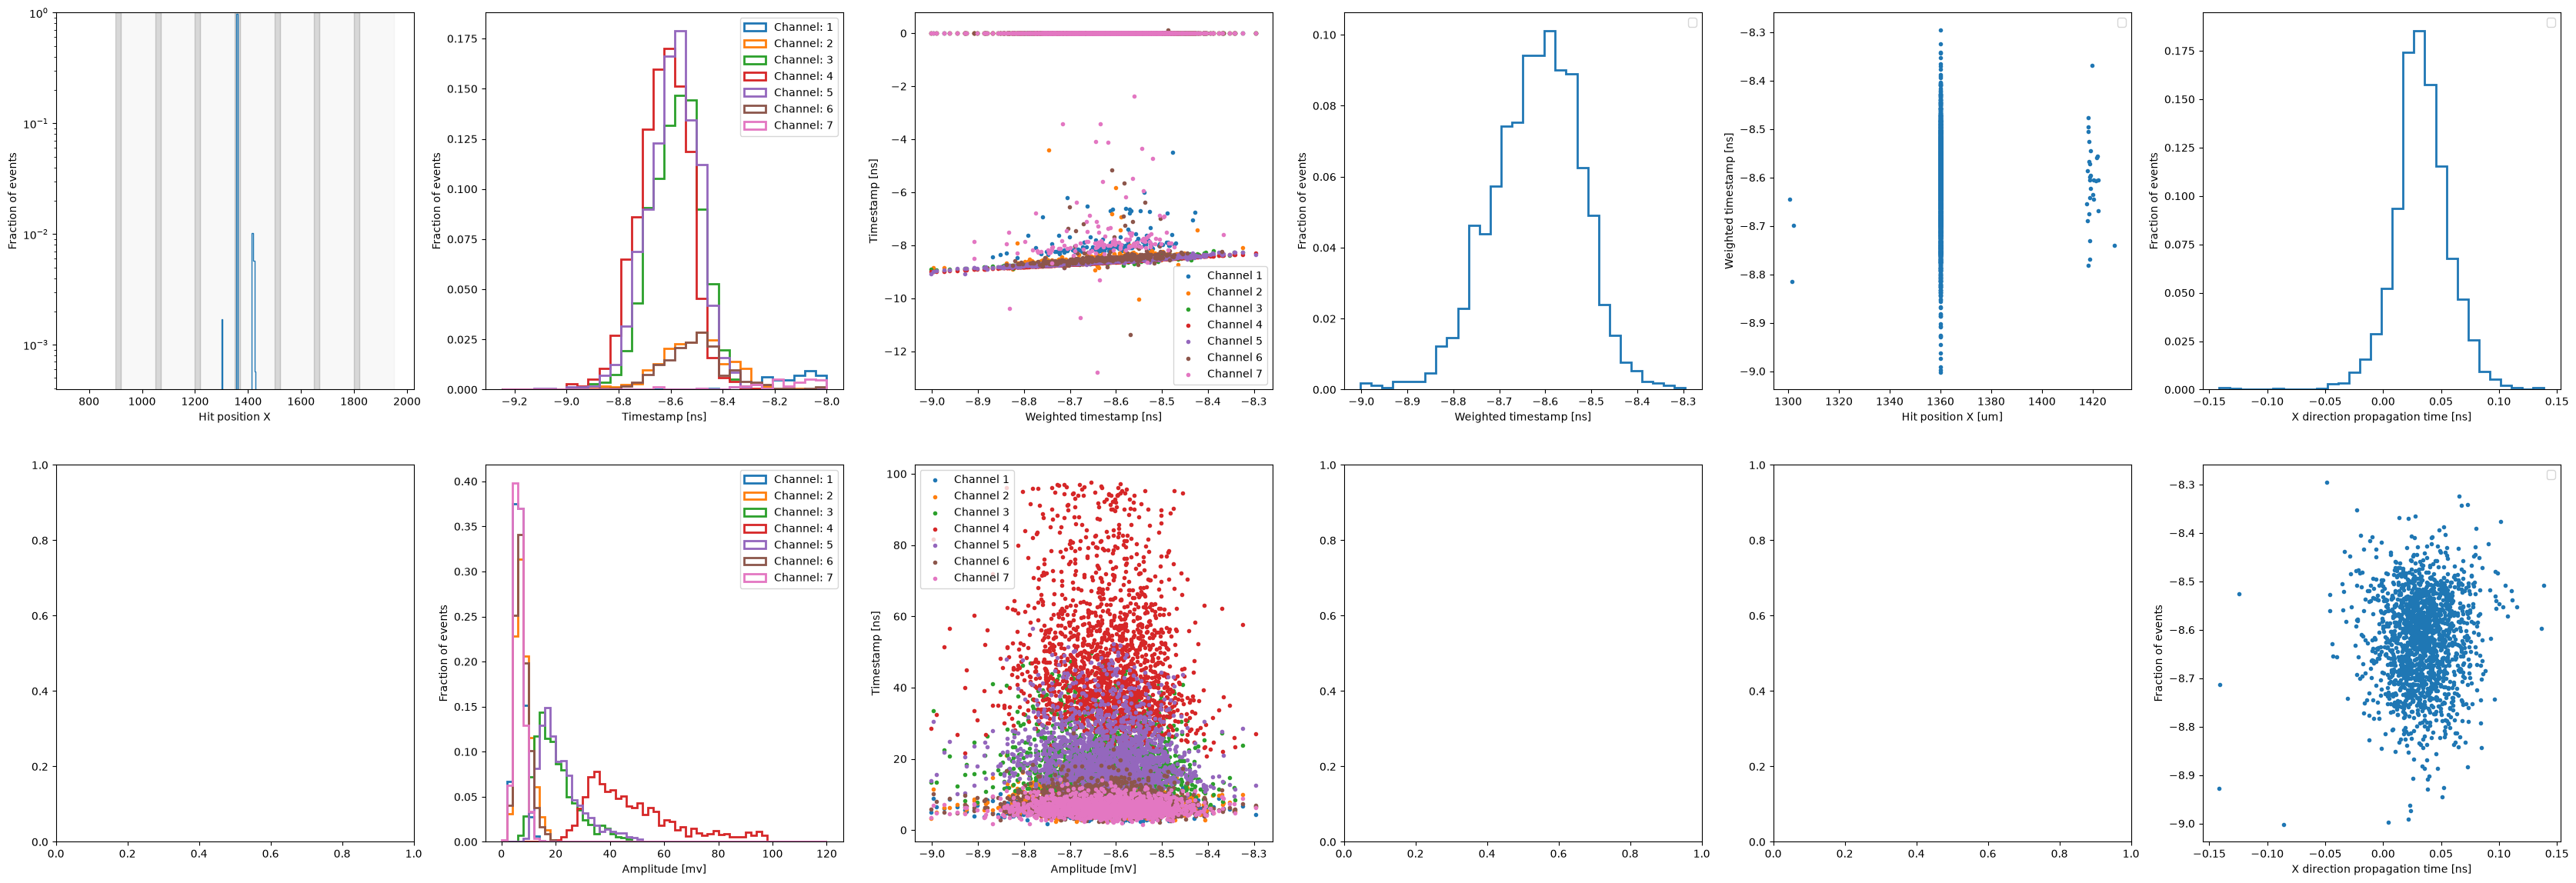

[1360.         1360.         1303.25134277 ... 1360.         1360.
 1360.        ]
0.03307397


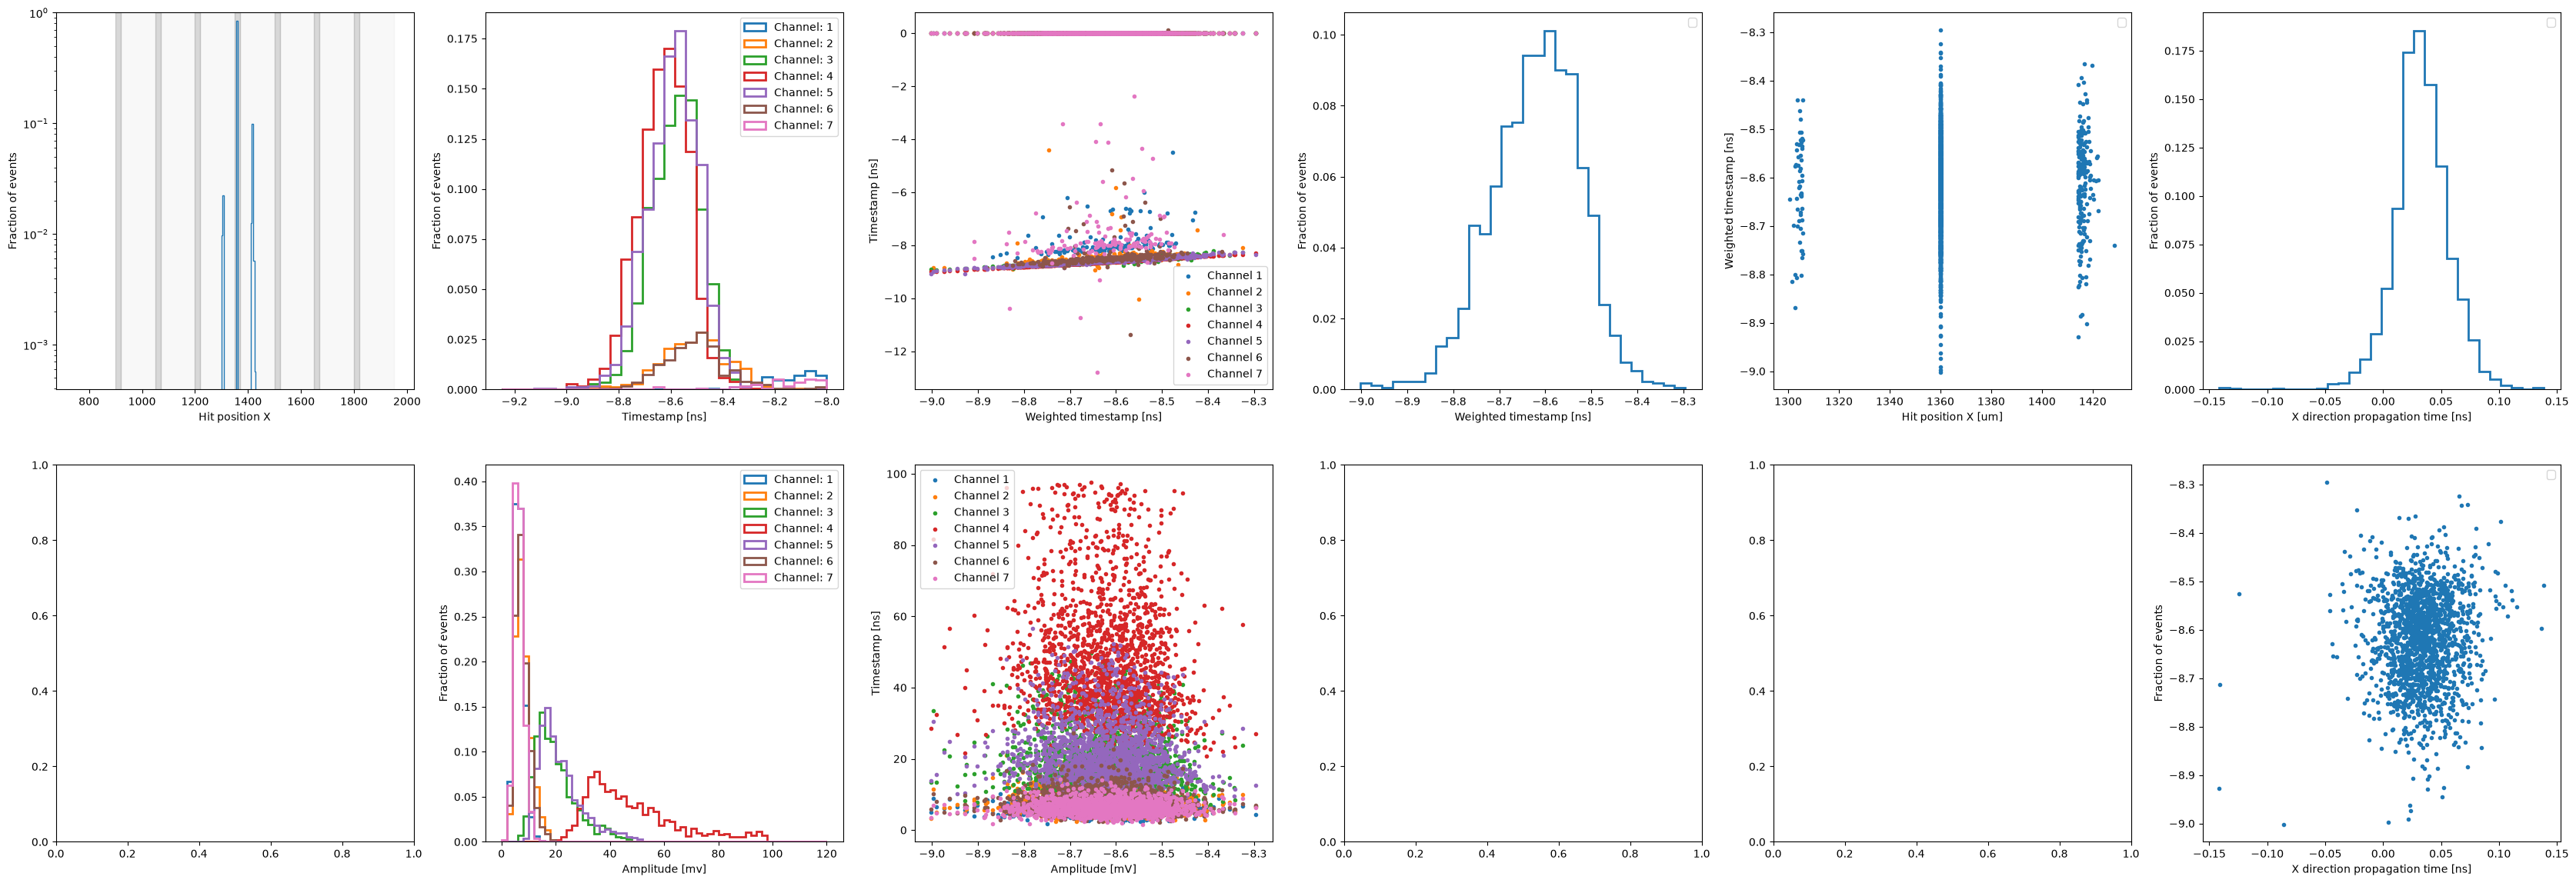

[1308.08921051 1360.         1303.25134277 ... 1360.         1412.3848381
 1308.3298111 ]
0.03307397


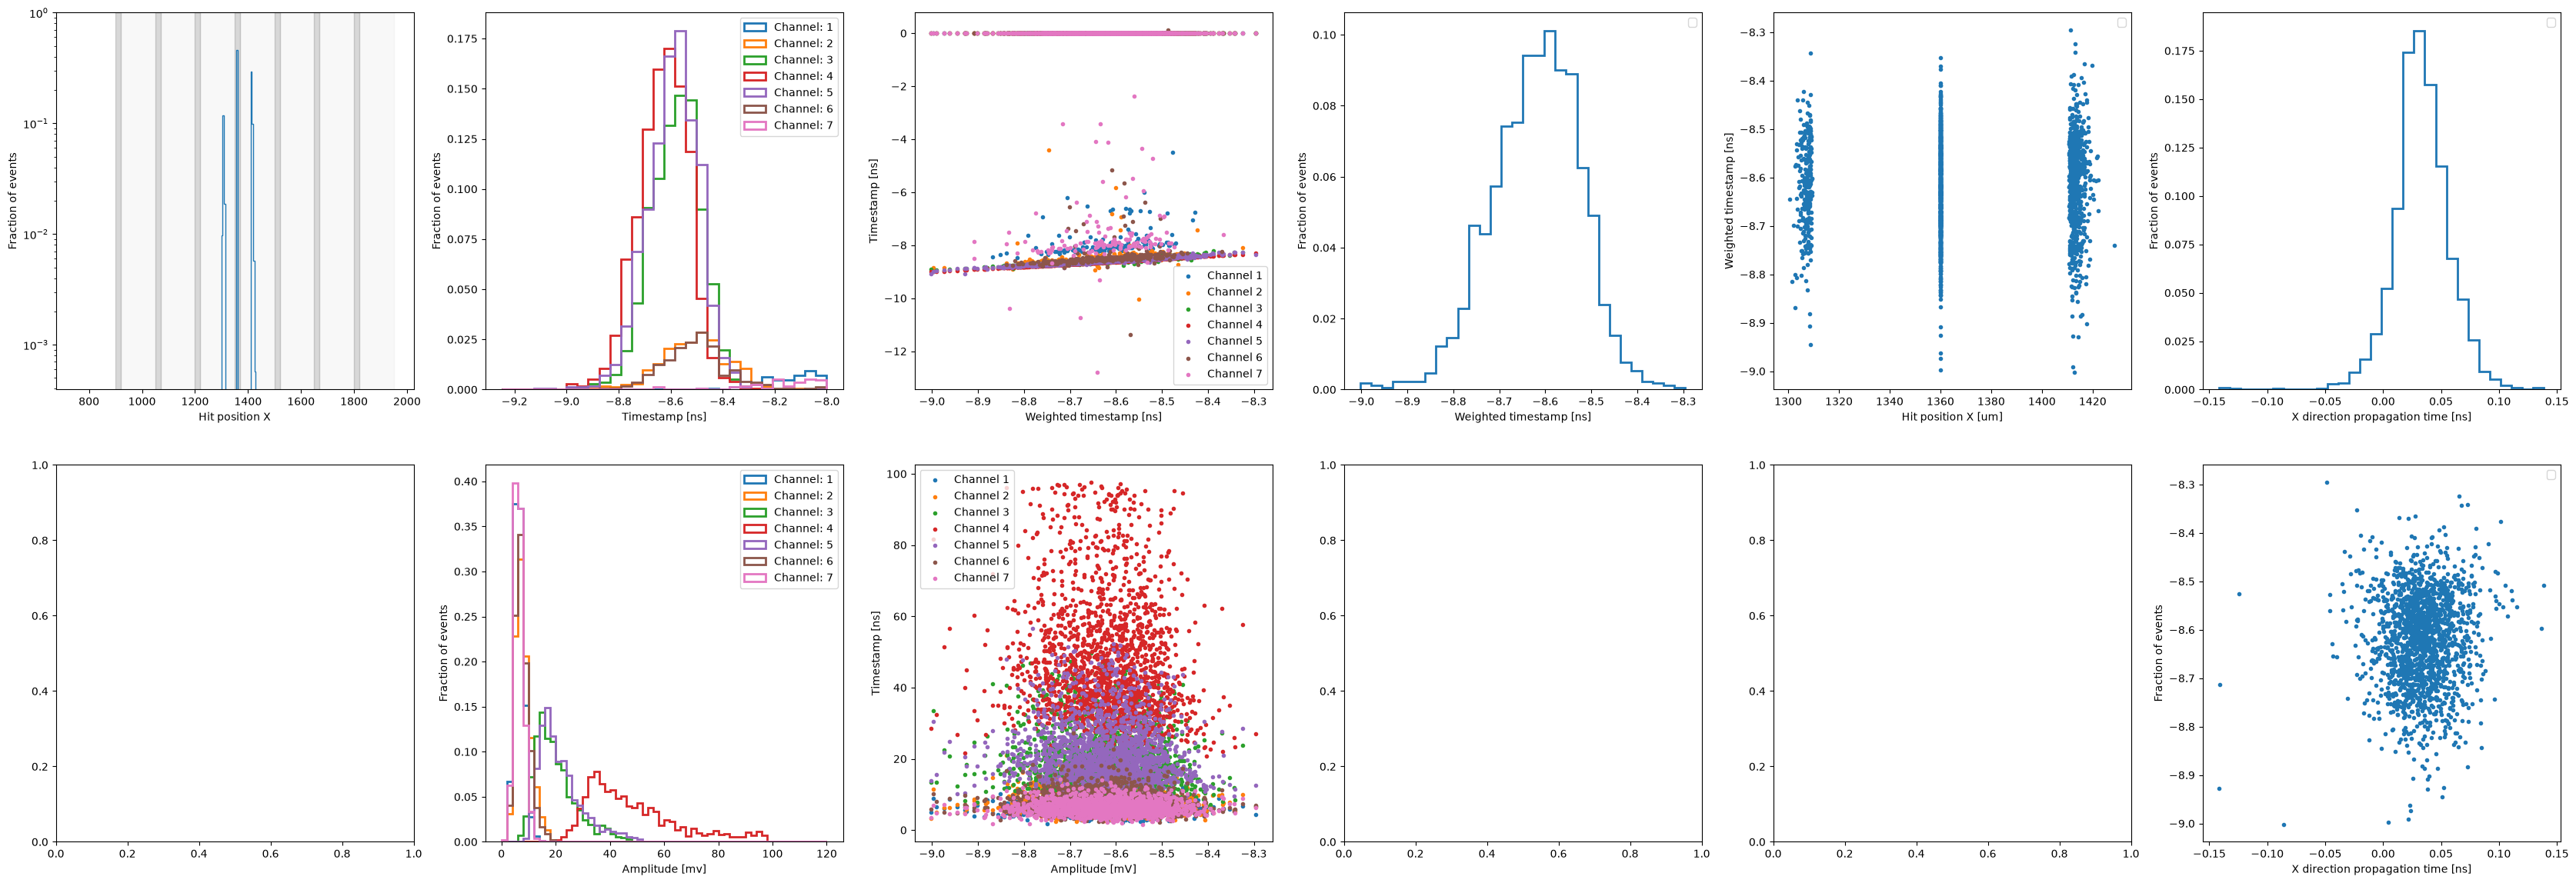

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


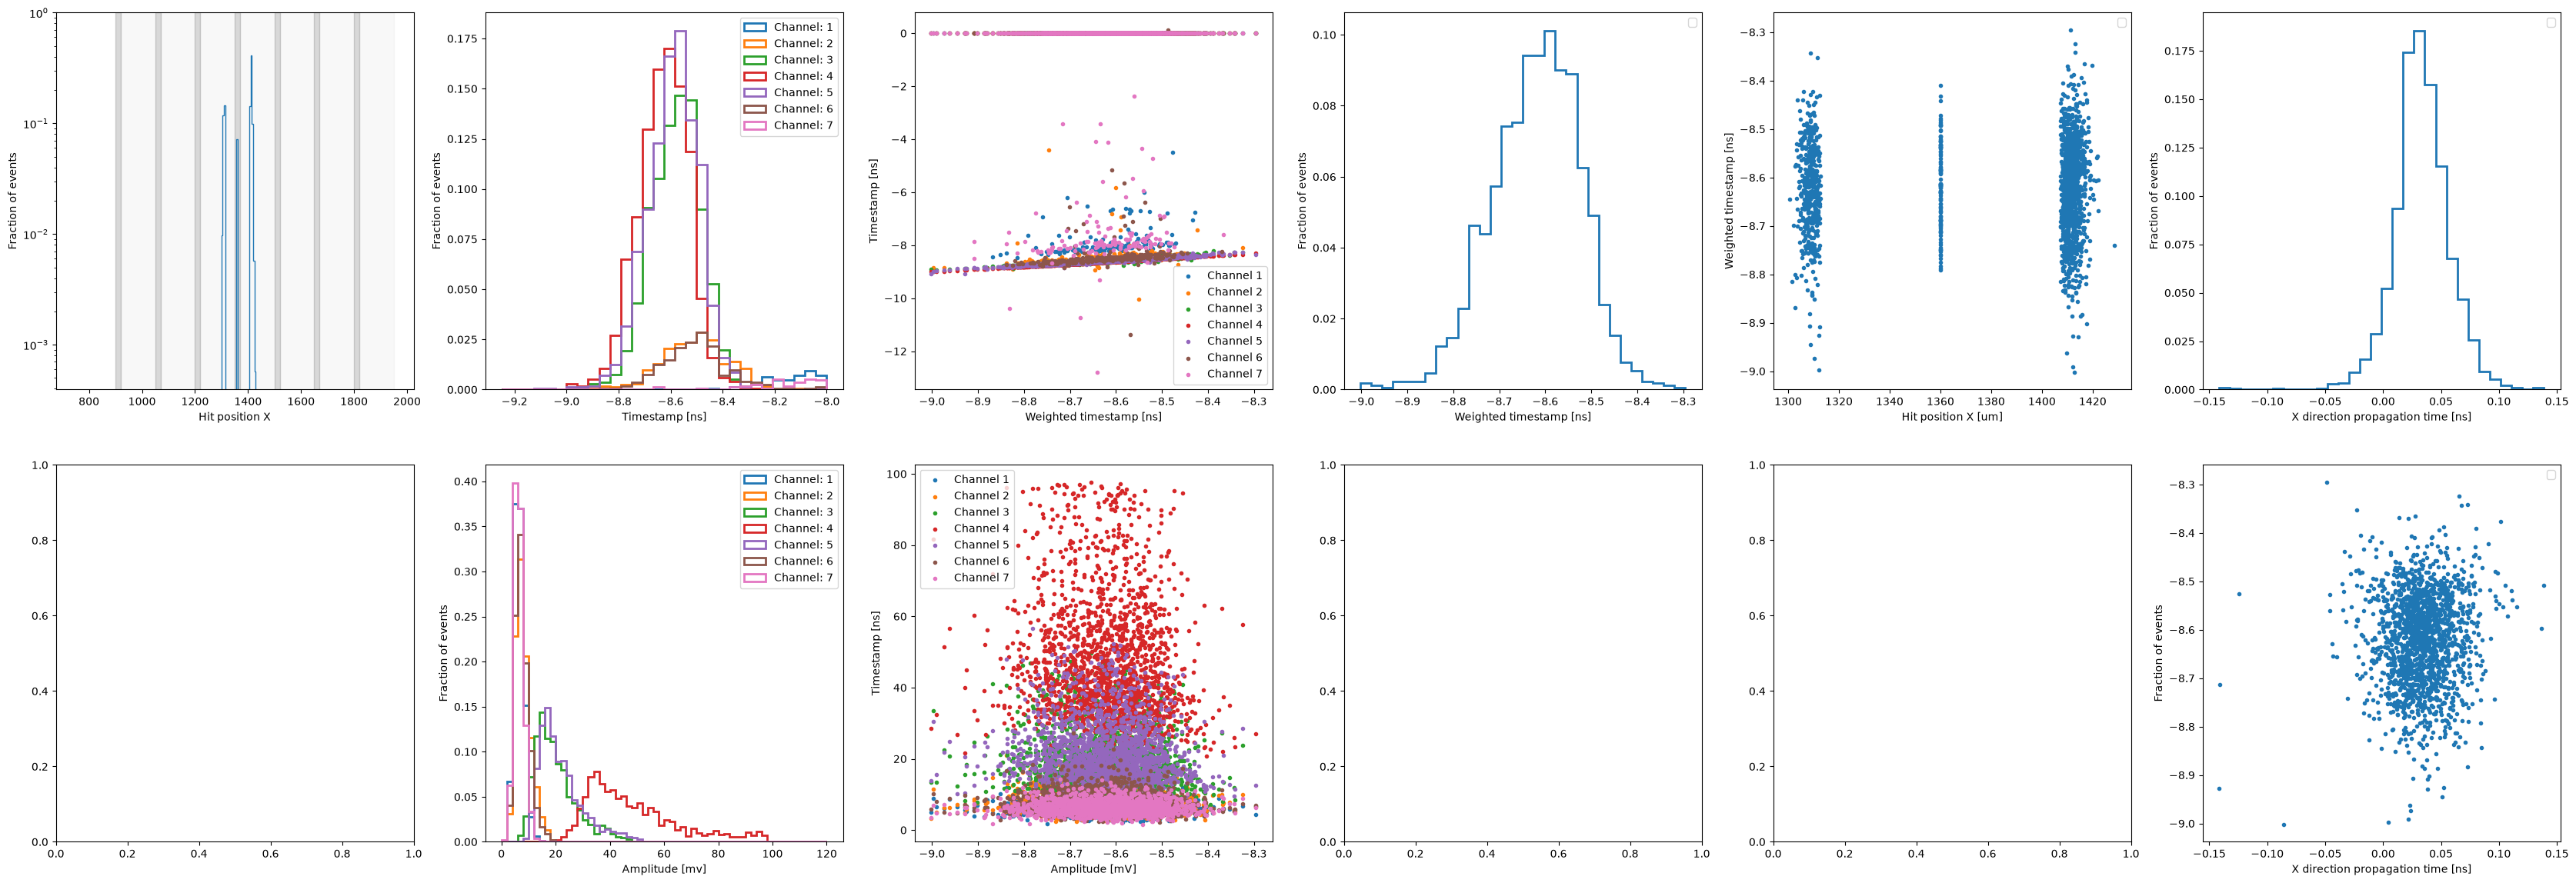

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


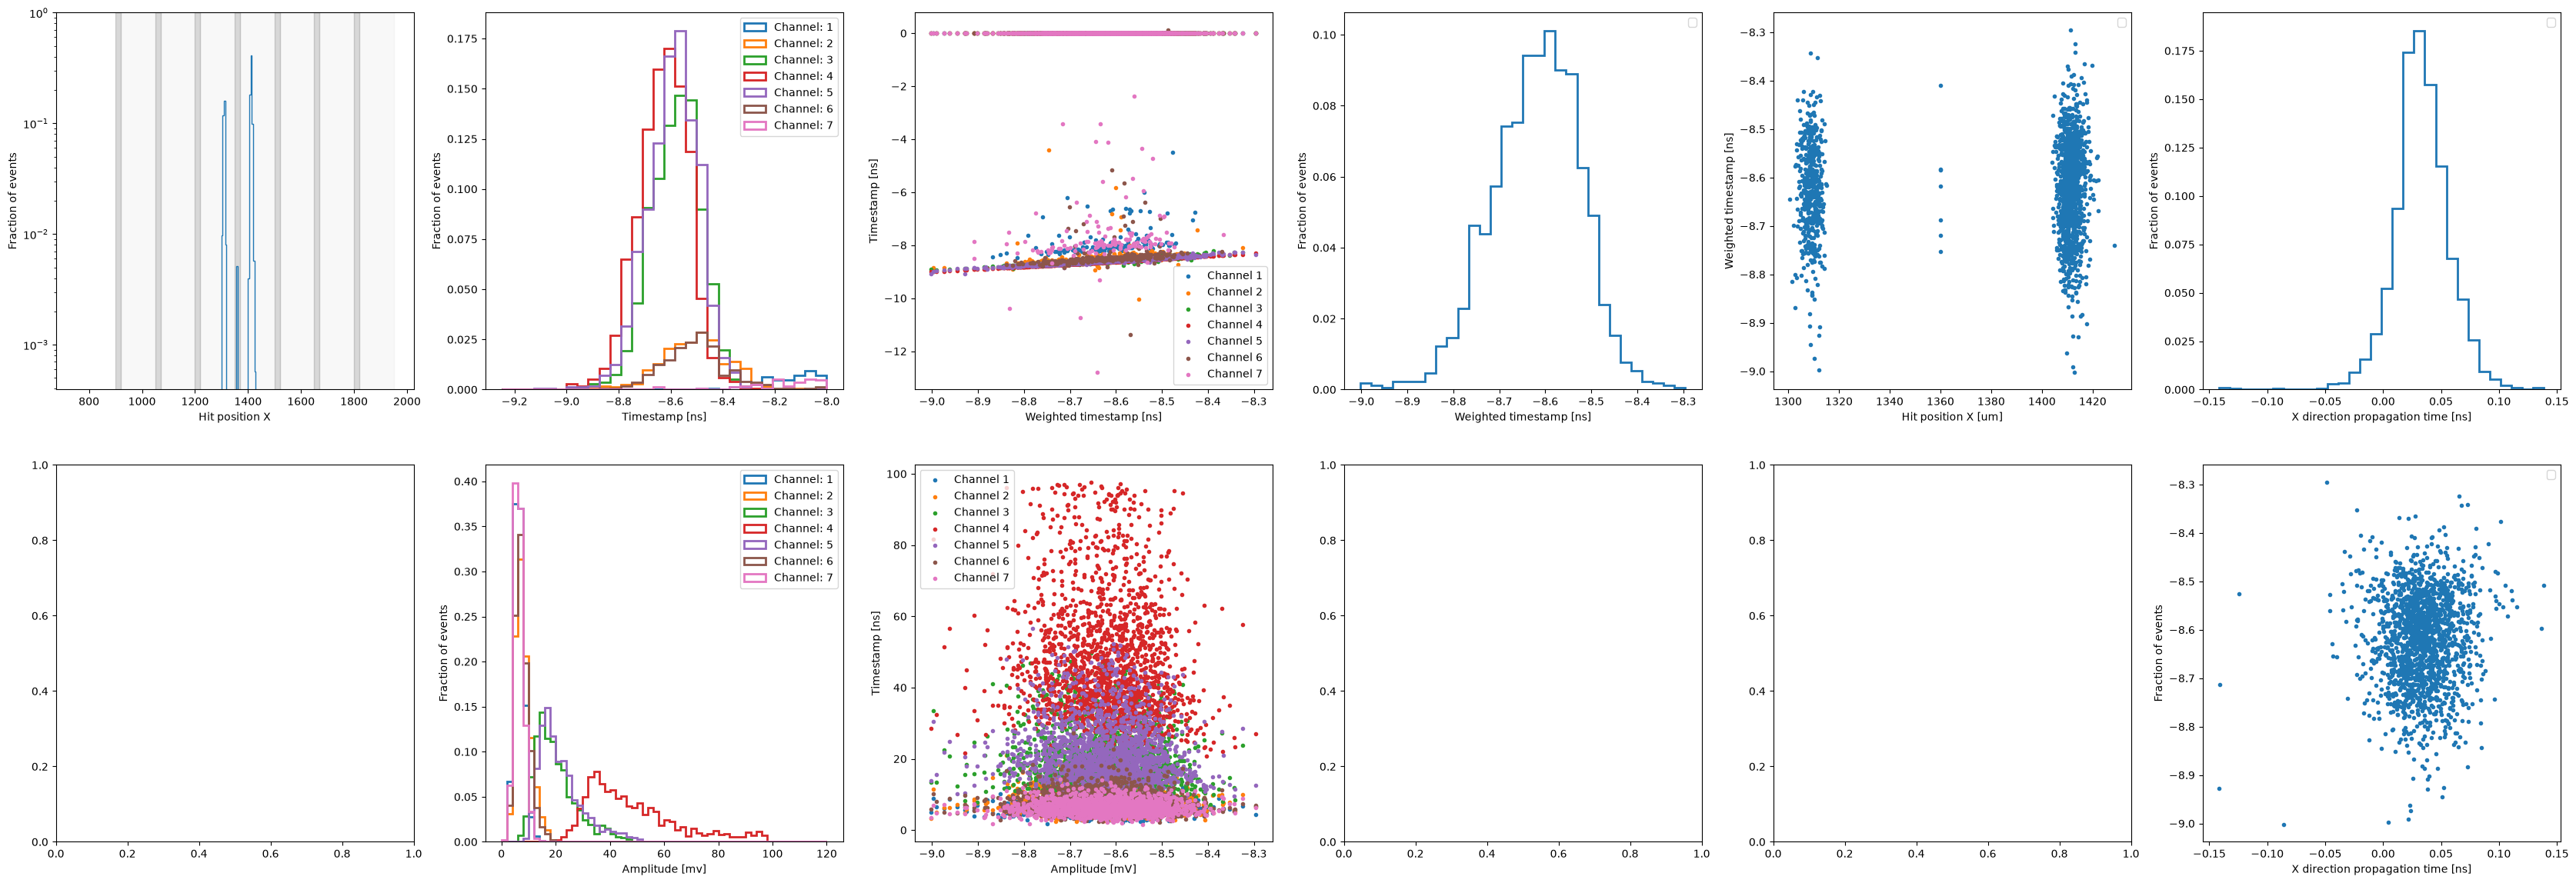

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


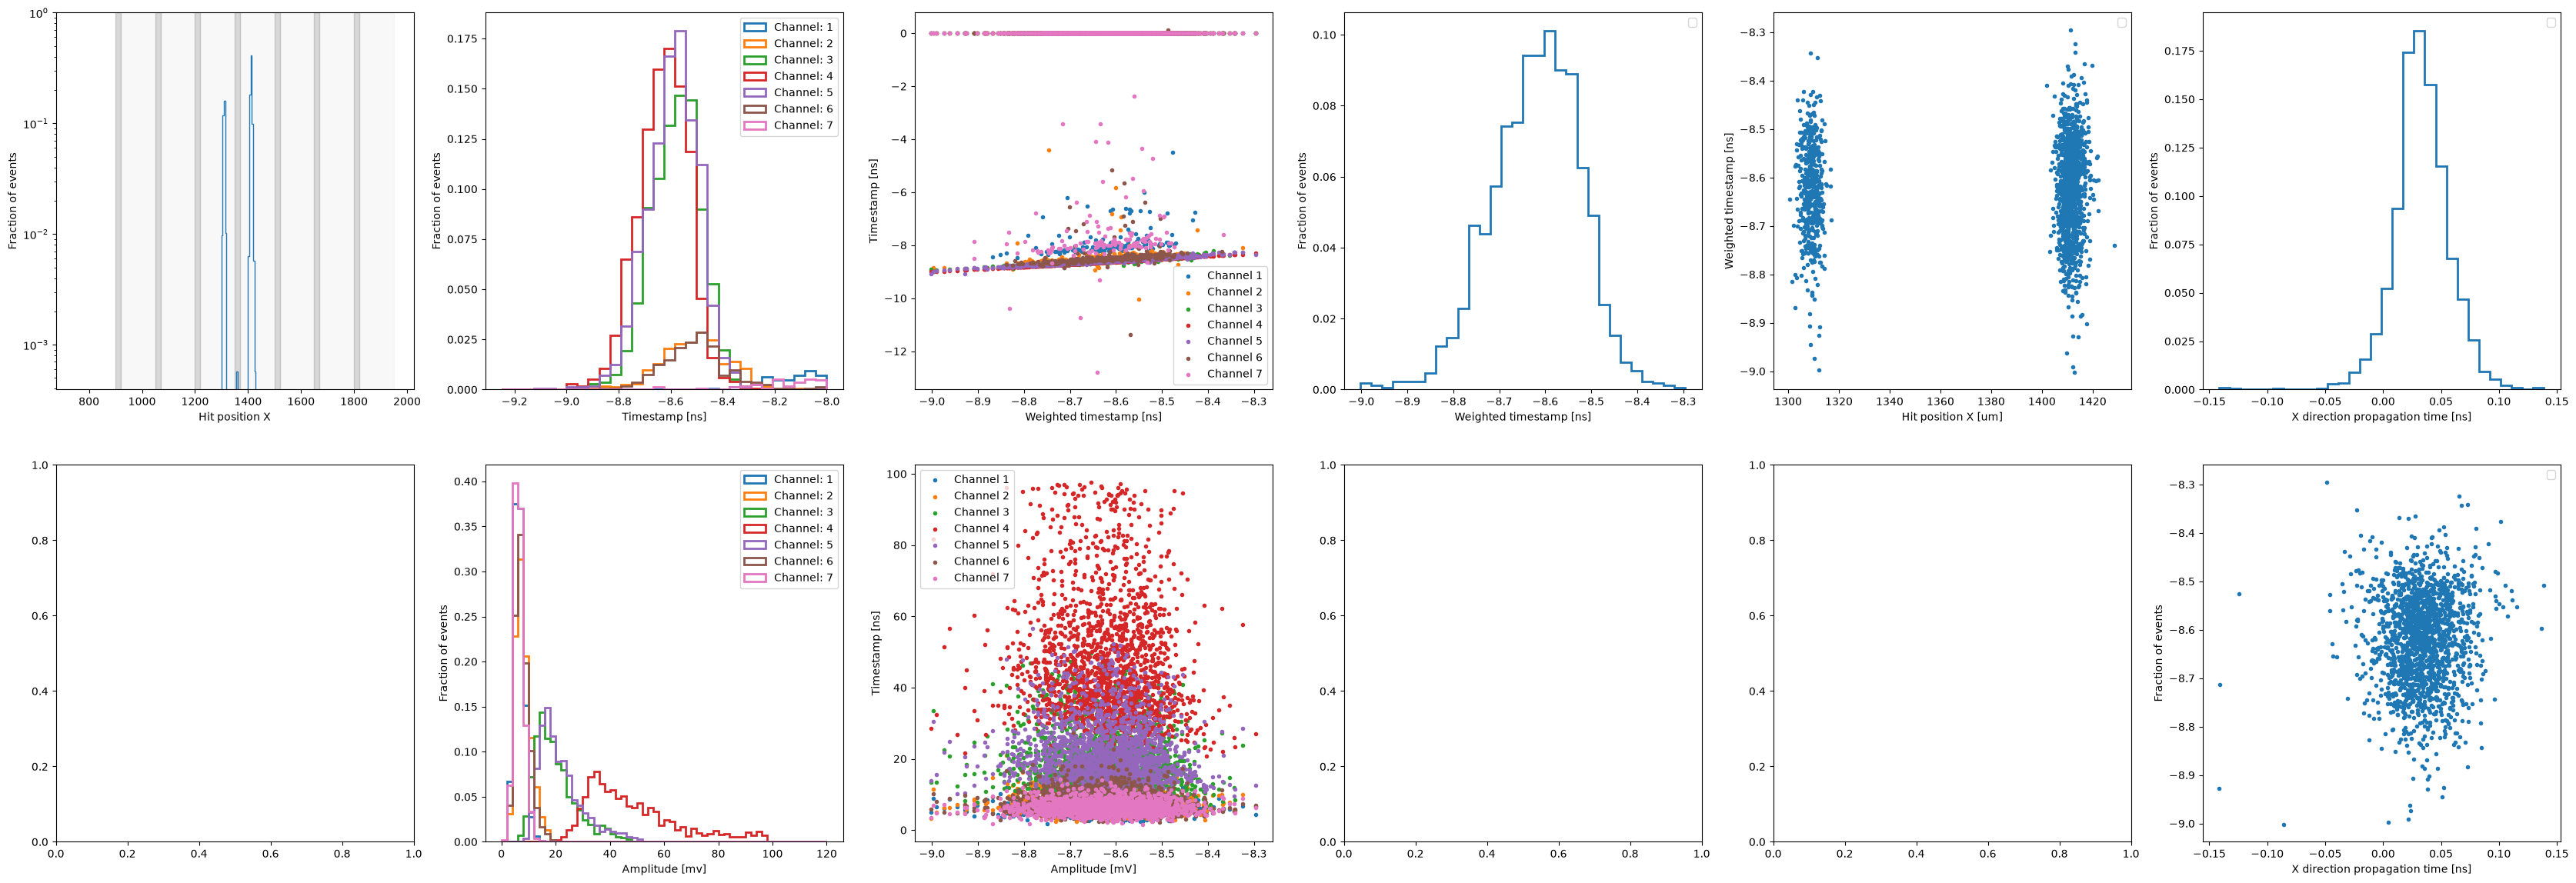

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


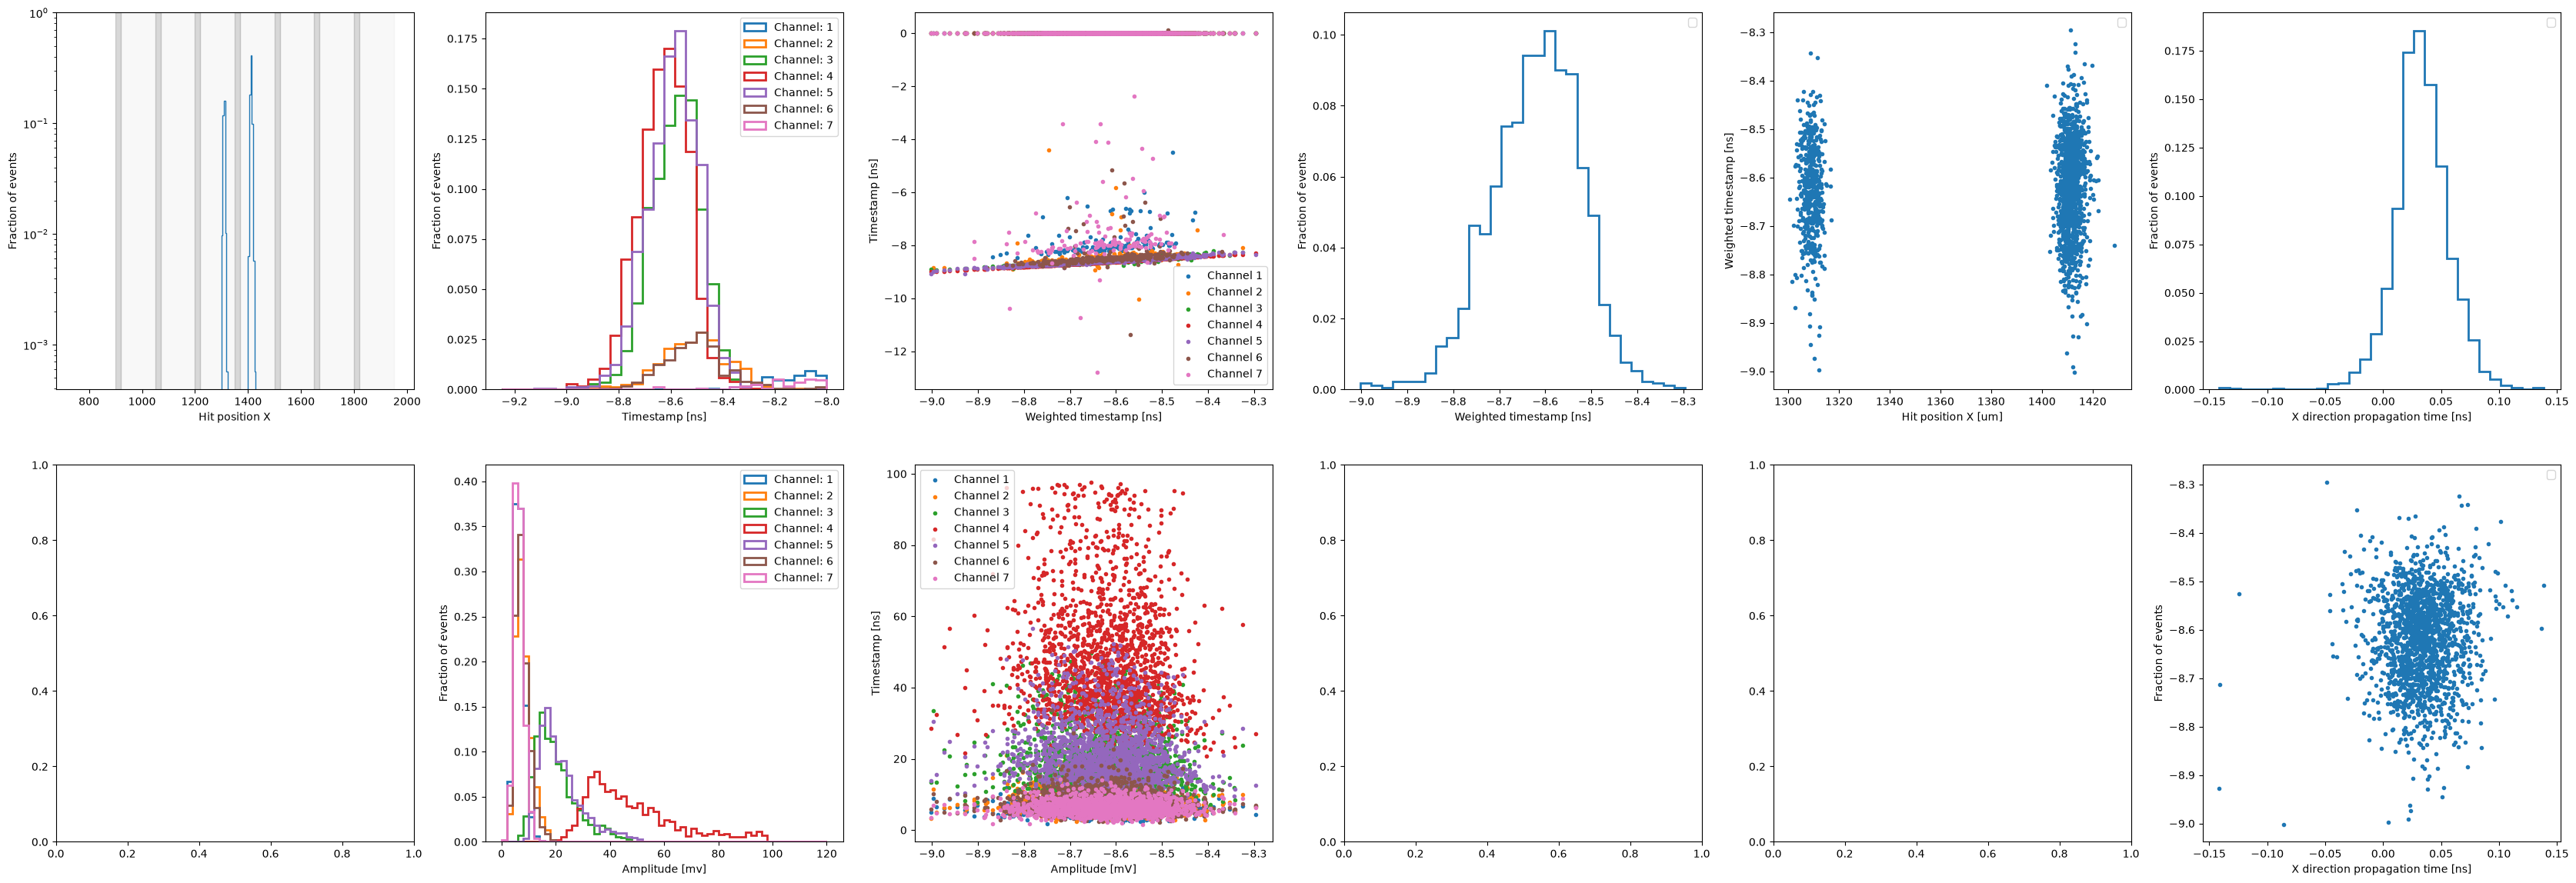

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


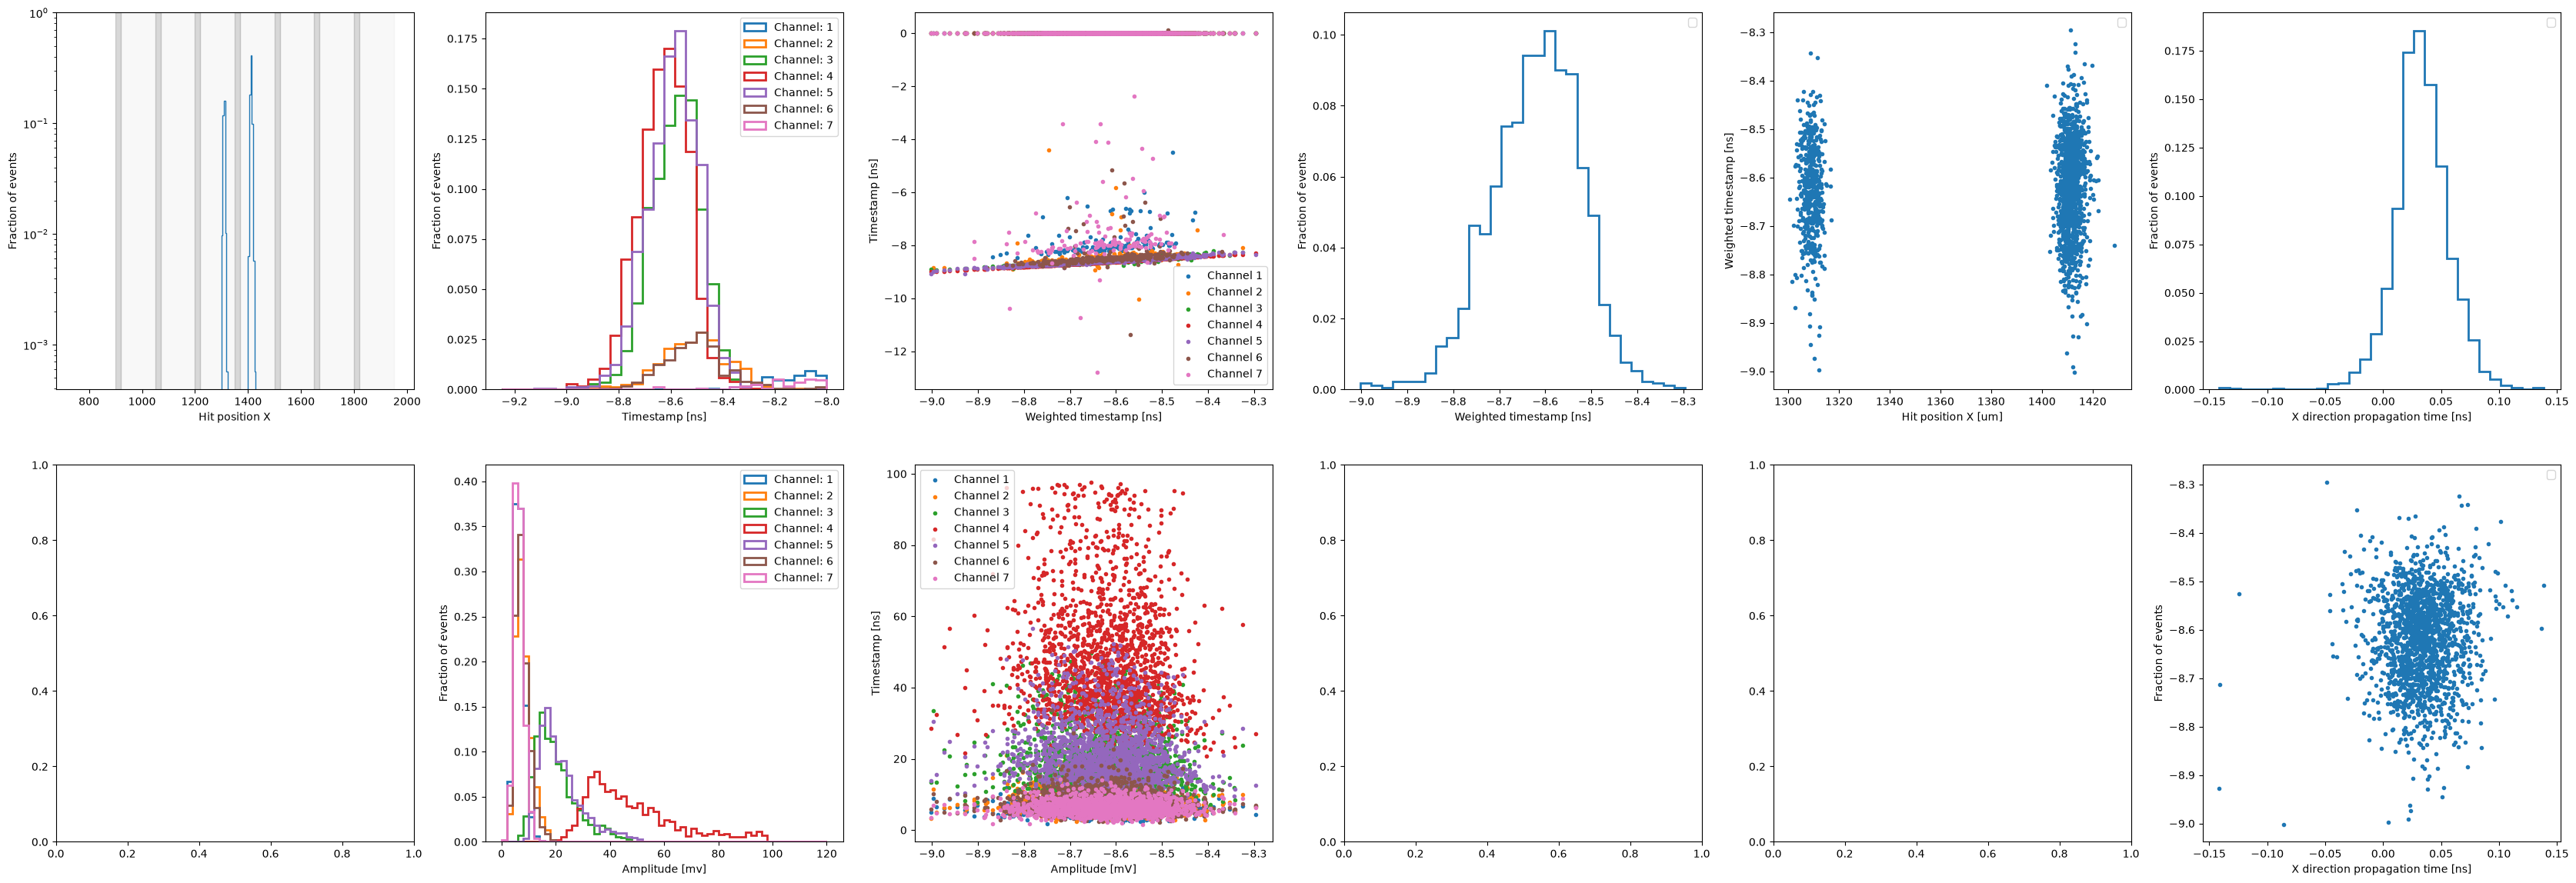

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


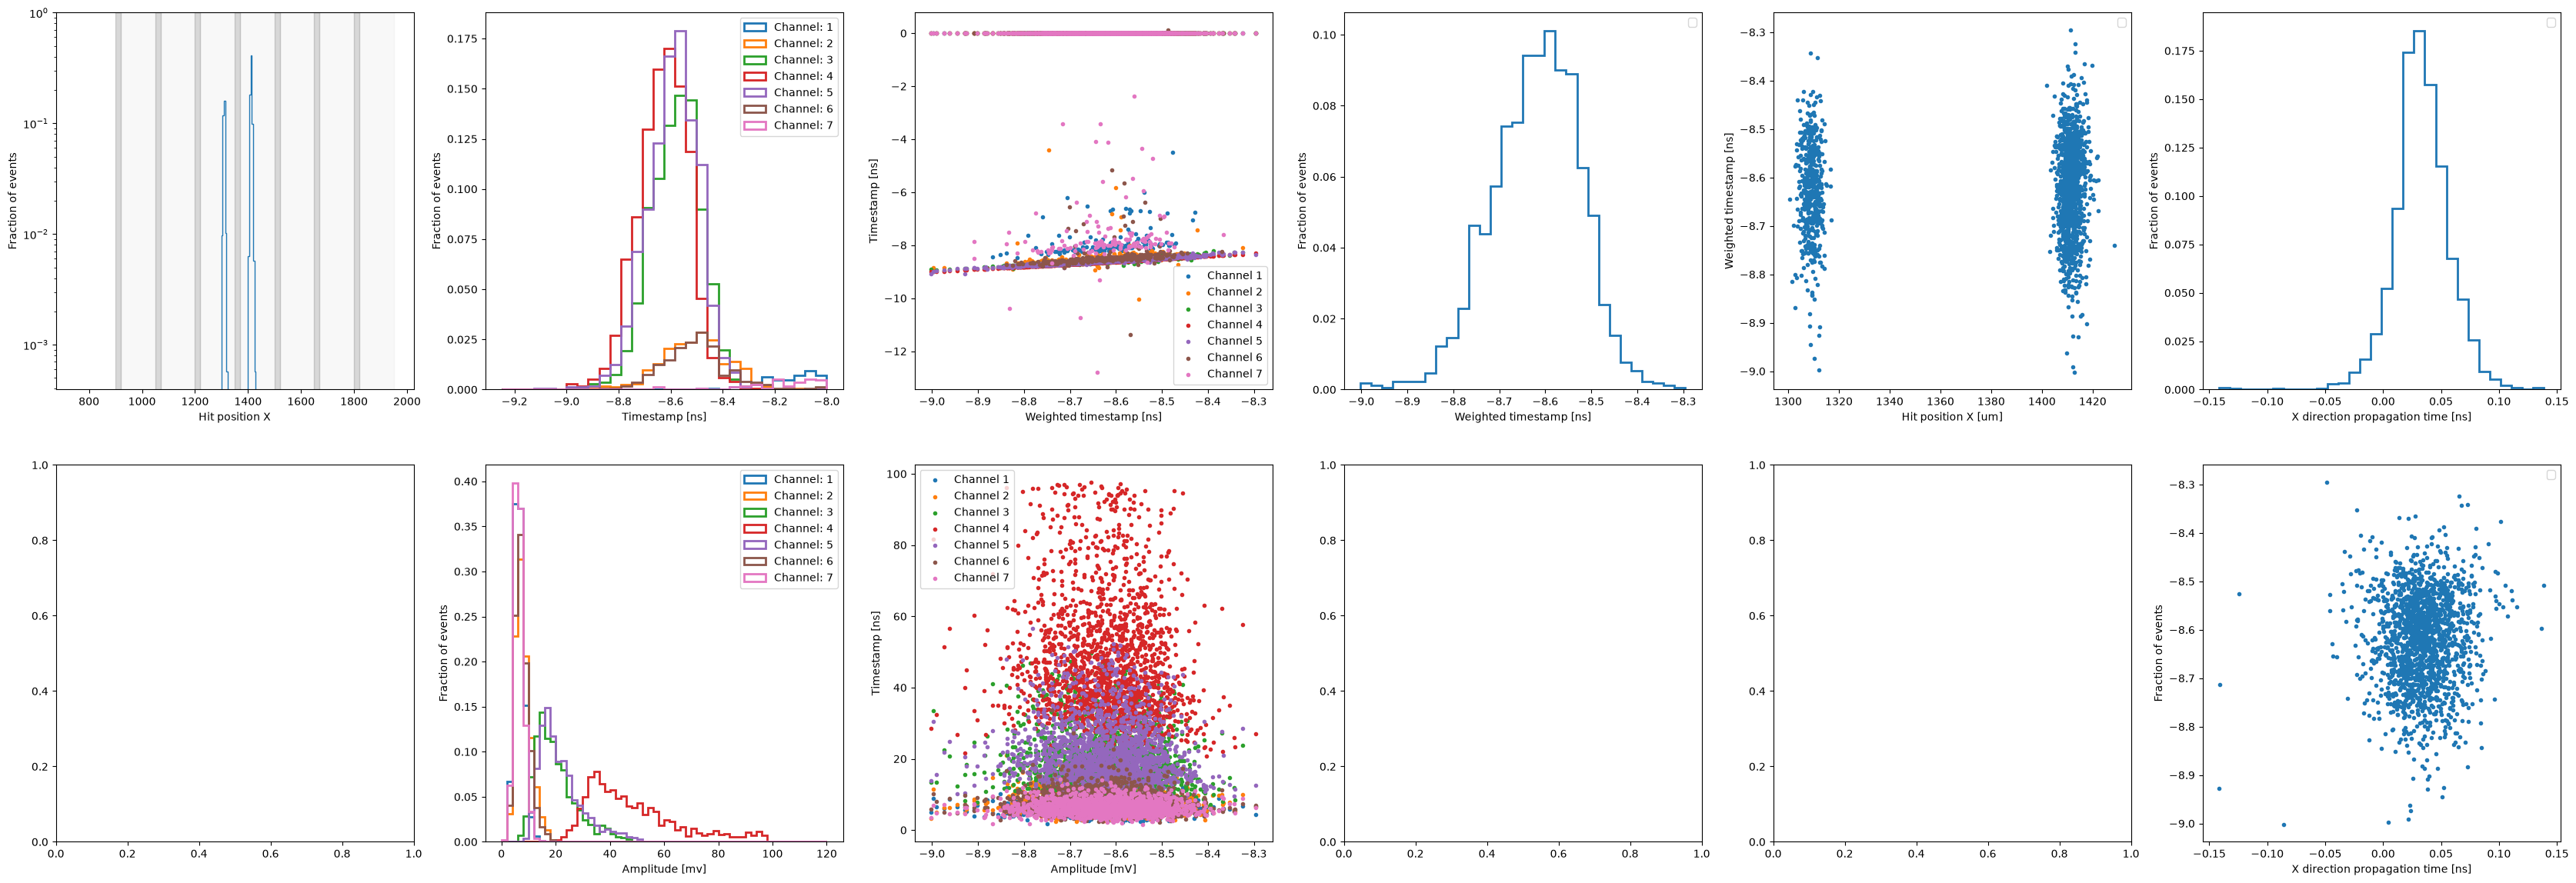

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


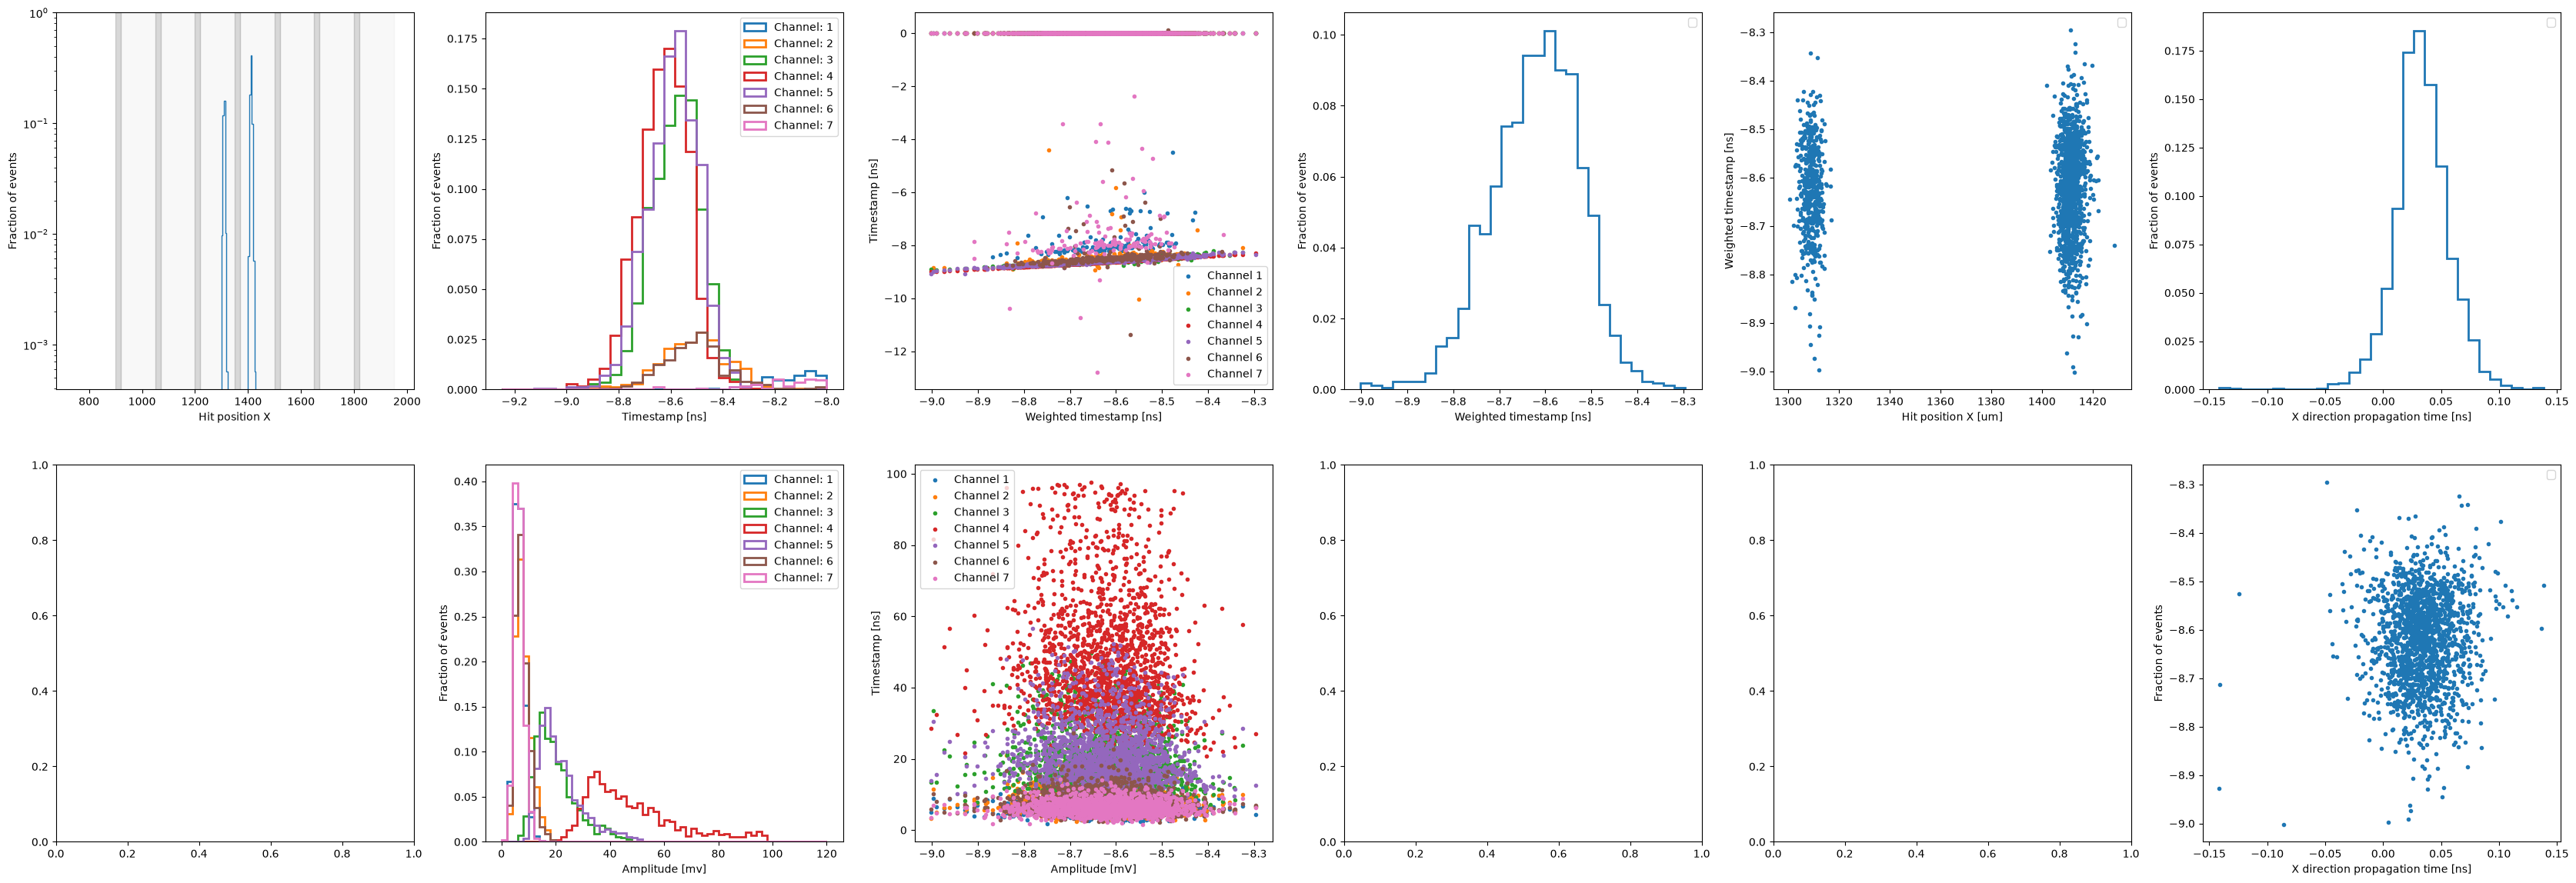

[1308.08921051 1408.3394165  1303.25134277 ... 1407.39487839 1412.3848381
 1308.3298111 ]
0.03307397


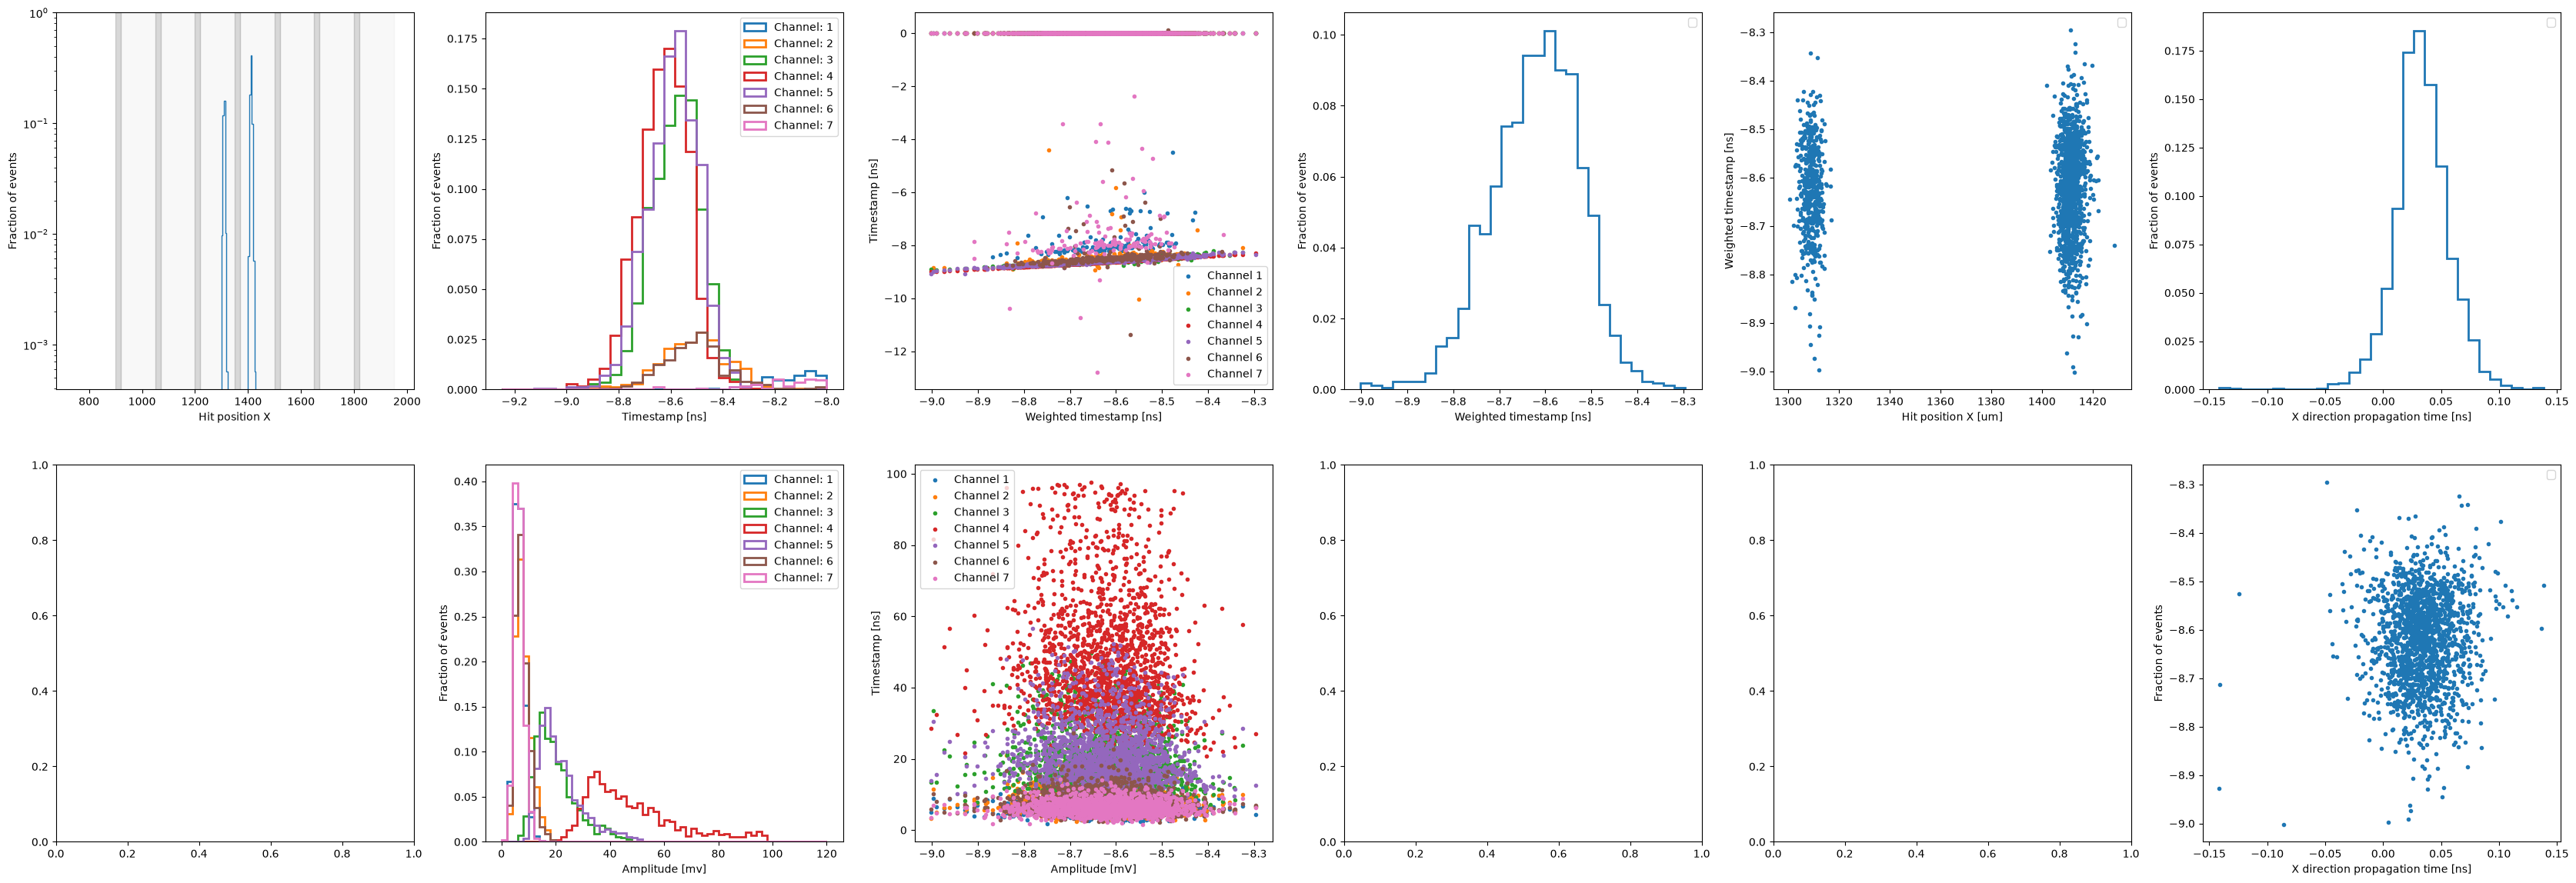

In [9]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

trigger_strip = 3
mcp_channel = 7

for f_i, f in enumerate(filenames):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    # print(pulse[0].fields)
    l = str(object_labels[f_i])
    channel[l] = pulse["channel"]
    time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]

print(amp.keys())

# key = "AC100W80_116V_Sr90_high_threshold_trigger"

for key in amp.keys():
    print(key)
    rows = 2
    cols = 6
    size = 7
    
    baseline_sel = (baseline_RMS[key][:,3] < 3)
    amp_sel = (amp[key][:,1] < 60)
    lead_strip = (amp[key][:,3]>amp[key][:,0]) & (amp[key][:,3]>amp[key][:,1]) & (amp[key][:,3]>amp[key][:,2]) & (amp[key][:,3]>amp[key][:,4]) & (amp[key][:,3]>amp[key][:,5]) & (amp[key][:,3]>amp[key][:,6])
    timestamp_sel = (timestamps[key][:,3]<-8) & (timestamps[key][:,4]<-8)
    # print(np.divide(amp[key][:,3], (amp[key][:,3] + amp[key][:,4] + amp[key][:,2])))
    print(amp[key][:,3])
    fraction_selection = ((amp[key][:,3] / (amp[key][:,3] + amp[key][:,4] + amp[key][:,2])) > 0.5)

    # Cuts on amplitudes
    # amp_cuts = (amp[key][:,0]>20) & (amp[key][:,5]>20)
    
    cuts = baseline_sel & amp_sel & lead_strip & fraction_selection & timestamp_sel # & amp_cuts
    
    channel[key]      = channel[key][cuts]
    time[key]         = time[key][cuts]
    integral[key]     = integral[key][cuts]
    risetime[key]     = risetime[key][cuts]
    amp[key]          = amp[key][cuts]
    baseline_RMS[key] = baseline_RMS[key][cuts]
    timestamps[key]   = timestamps[key][cuts]
    
    # Draw the strips
    sensor_pitch = 3000 # um
    n_strips = 20
    n_conn_strips = 7
    strip_width = 20 # int(key.split("W")[1].split("_")[0])
    strip_gap = sensor_pitch/n_strips - strip_width
    range_start = 6
    range_end = range_start + n_conn_strips - 1
    n_displays = 0
        
    for ft in np.linspace(0.5, 0.9, 16):
        fig, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
        est_hit_x_position = []
        weighted_time = []
        x_propagation_time = []
        for i in range(len(amp[key])):
            # index, rel_dist = get_x_position(amp[i], strip_gap)
            
            channel_mask = [True, True, True, True, True, True, True, False] # Masking the MCP
        
            rel_x_position, strips, fraction = get_x_position(amp[key][i][channel_mask], gap = strip_gap, width = strip_width, fraction_threshold = ft)
            est_hit_x_position.append(range_start*(strip_width + strip_gap) + rel_x_position)
            weighted_time     .append(get_weighted_time     (amp[key][i][channel_mask], timestamps[key][i][channel_mask]))
            x_propagation_time.append(get_x_propagation_time(amp[key][i][channel_mask], timestamps[key][i][channel_mask]))
        
            if (i < n_displays):
                fig_tmp, ax_tmp = plt.subplots(1, 1, figsize = (5, 5))
                ax_tmp = draw_grid(ax_tmp)
                ax_tmp.plot([range_start*(strip_width + strip_gap), range_start*(strip_width + strip_gap)], [0, 1], "--")
                ax_tmp.plot([est_hit_x_position[-1], est_hit_x_position[-1]], [0, 1], "--")
                ax_tmp.scatter([est_hit_x_position[-1]], [0.5], label = f"X position {np.round(est_hit_x_position[-1], 3)}\nFraction: {np.round(fraction, 3)}\nStrip index: {strips}")
                ax_tmp.legend()
                fig_tmp.savefig(f"./Position_plots/grid_{i}.png")

        weighted_time      = np.array(weighted_time)
        x_propagation_time = np.array(x_propagation_time)
        est_hit_x_position = np.array(est_hit_x_position)

        print(est_hit_x_position)
        
        ax[0][0] = draw_grid(ax[0][0])
        ax[0][0].set_yscale("log")
        ax[0][0].hist(est_hit_x_position, histtype = "step", bins = 250, range = (800, 2000), weights = np.ones(len(amp[key])) / len(amp[key]))
        # ax[0][0].set_xlim(1250, 1500) # len(amp[key])
        ax[0][0].set_ylim(0, 1) # len(amp[key])

        tmp_cut = (weighted_time<-8)
        weights = np.ones(len(amp[key][tmp_cut])) / len(amp[key][tmp_cut])

        for i in range(7):
            # if (i != 3 and i != 4): continue
            ax[0][1].hist(timestamps[key][:,i][tmp_cut], histtype = "step", weights = weights, label = f"Channel: {i+1}", range = (-9.25, -8), bins = 30, linewidth=2)
        ax[0][1].set_xlabel("Timestamp [ns]")
        ax[0][1].set_ylabel("Fraction of events")
        ax[0][1].legend()

        for i in range(7):
            # if (i != 3 and i != 4): continue
            ax[1][1].hist(amp[key][:,i][tmp_cut], histtype = "step", weights = weights, label = f"Channel: {i+1}", range = (0, 120), bins = 60, linewidth=2)
        ax[1][1].set_xlabel("Amplitude [mv]")
        ax[1][1].set_ylabel("Fraction of events")
        ax[1][1].legend()

        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,0][tmp_cut], marker = ".", label = "Channel 1")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,1][tmp_cut], marker = ".", label = "Channel 2")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,2][tmp_cut], marker = ".", label = "Channel 3")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,3][tmp_cut], marker = ".", label = "Channel 4")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,4][tmp_cut], marker = ".", label = "Channel 5")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,5][tmp_cut], marker = ".", label = "Channel 6")
        ax[0][2].scatter(weighted_time[tmp_cut], timestamps[key][:,6][tmp_cut], marker = ".", label = "Channel 7")
        ax[0][2].set_xlabel("Weighted timestamp [ns]")
        ax[0][2].set_ylabel("Timestamp [ns]")
        ax[0][2].legend()
        
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,0][tmp_cut], marker = ".", label = "Channel 1")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,1][tmp_cut], marker = ".", label = "Channel 2")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,2][tmp_cut], marker = ".", label = "Channel 3")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,3][tmp_cut], marker = ".", label = "Channel 4")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,4][tmp_cut], marker = ".", label = "Channel 5")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,5][tmp_cut], marker = ".", label = "Channel 6")
        ax[1][2].scatter(weighted_time[tmp_cut], amp[key][:,6][tmp_cut], marker = ".", label = "Channel 7")
        ax[1][2].set_xlabel("Amplitude [mV]")
        ax[1][2].set_ylabel("Timestamp [ns]")
        ax[1][2].legend()
        
        ax[0][3].hist(weighted_time[tmp_cut], histtype = "step", weights = weights, bins = 30, linewidth=2)
        ax[0][3].set_xlabel("Weighted timestamp [ns]")
        ax[0][3].set_ylabel("Fraction of events")
        ax[0][3].legend()

        # ax[4] = draw_grid(ax[4])
        ax[0][4].scatter(est_hit_x_position[tmp_cut], weighted_time[tmp_cut], marker = ".")
        ax[0][4].set_xlabel("Hit position X [um]")
        ax[0][4].set_ylabel("Weighted timestamp [ns]")
        ax[0][4].legend()

        print(np.mean(x_propagation_time[tmp_cut]))
        
        ax[0][5].hist(x_propagation_time[tmp_cut], histtype = "step", weights = weights, bins = 30, linewidth=2)
        ax[0][5].set_xlabel("X direction propagation time [ns]")
        ax[0][5].set_ylabel("Fraction of events")
        ax[0][5].legend()

        ax[1][5].scatter(x_propagation_time[tmp_cut], weighted_time[tmp_cut], marker = ".")
        ax[1][5].set_xlabel("X direction propagation time [ns]")
        ax[1][5].set_ylabel("Fraction of events")
        ax[1][5].legend()
        
        # ax[4].hist(x_propagation_time[tmp_cut], histtype = "step", weights = weights, bins = 60, linewidth=2)
        # ax[4].set_xlabel("X direction propagation time [ns]")
        # ax[4].set_ylabel("Fraction of events")
        # ax[4].legend()

        # for i in range(7):
        #     ax[4].hist(amp[key][:,i][tmp_cut], histtype = "step", weights = weights, label = f"Channel: {i+1}", range = (0, 100), bins = 120, linewidth=2)
        # ax[4].set_xlabel("Amplitude")
        # ax[4].set_ylabel("Fraction of events")
        # ax[4].legend()
        
        plt.show()
